# PRCP-1018: Bike Rental Demand Prediction

## 1. Business Understanding

### 1.1 Project Overview

Bike-sharing systems have become an important part of modern urban transportation. They provide an affordable, convenient and environmentally friendly alternative to traditional transportation methods.

These systems allow customers to rent bicycles from designated locations and return them at different stations. The rental process is automated, generating valuable data about customer usage, rental patterns, environmental conditions and seasonal variations.

However, the demand for rental bicycles is not constant. It can fluctuate depending on several factors, including weather conditions, temperature, humidity, seasons, holidays and working days.

Understanding these patterns can help bike-sharing companies make better operational and business decisions.

This project focuses on analyzing historical bike-sharing data and developing machine learning models to predict daily bike rental demand based on environmental and seasonal conditions.

### 1.2 Business Problem Statement

Bike-sharing companies face the challenge of maintaining an appropriate number of bicycles to meet customer demand.

Insufficient bicycle availability can result in lost rental opportunities and dissatisfied customers, whereas an excessive number of unused bicycles can increase operational and maintenance costs.

The objective of this project is to analyze historical bike rental data, identify the factors influencing rental demand and develop predictive models capable of estimating the daily number of bike rentals using environmental and seasonal information.

The project aims to transform historical rental data into meaningful business insights and reliable demand predictions.

### 1.3 Project Objectives

The primary objectives of this project are:

1. To perform comprehensive exploratory data analysis on the provided bike-sharing datasets.
2. To understand daily and hourly bike rental patterns.
3. To investigate the relationship between environmental conditions and rental demand.
4. To identify seasonal, monthly, weekly and weather-related demand variations.
5. To identify and address data quality issues, inconsistencies and missing values, if present.
6. To perform feature engineering and prepare the dataset for machine learning.
7. To develop and evaluate multiple regression models for predicting daily bike rental counts.
8. To compare model performance using appropriate regression evaluation metrics.
9. To identify the most suitable predictive model for potential business deployment.
10. To provide actionable recommendations that can help improve bicycle availability and operational planning.

### 1.4 Business Applications

The results of this analysis can support bike-sharing companies in several business areas:

**1. Demand Forecasting**

Estimate the expected number of daily bicycle rentals to improve demand planning.

**2. Fleet Management**

Maintain an appropriate number of bicycles to reduce shortages and unnecessary idle inventory.

**3. Resource Allocation**

Improve the allocation of bicycles across operational locations based on expected demand, wherever location-level information is available.

**4. Weather-Based Planning**

Understand how temperature, humidity, wind speed and weather conditions influence customer rental behaviour.

**5. Seasonal Planning**

Identify seasonal demand patterns and prepare operational strategies for periods of high and low bicycle usage.

**6. Operational Cost Optimization**

Reduce unnecessary maintenance, storage and operational costs through better demand estimation.

### 1.5 Analytical Approach

The project follows a structured data science workflow consisting of:

- Data Collection and Understanding
- Data Quality Assessment
- Exploratory Data Analysis (EDA)
- Data Cleaning and Preprocessing
- Feature Engineering
- Machine Learning Model Development
- Model Evaluation and Comparison
- Final Business Recommendations

The final objective is to develop a reliable regression model that can estimate daily bike rental demand and provide meaningful insights for business decision-making.

### 1.6 Project Scope

The project uses two datasets provided with the problem statement:

| Dataset | Description |
|---|---|
| day.csv | Daily bike rental records |
| hour.csv | Hourly bike rental records |

The datasets contain information about rental dates, seasons, weather conditions, temperature, humidity, wind speed and customer rental counts.

The primary prediction target is:

**cnt:** Total number of rental bikes, including both casual and registered users.

The analysis will primarily focus on daily demand prediction using `day.csv`, while `hour.csv` will support additional exploratory analysis of hourly rental behaviour.

The scope includes historical data analysis and predictive modelling. Real-time demand forecasting and live integration with bike-sharing systems are outside the scope of this project.

# 2. Data Collection

### 2.1 Dataset Source

The dataset used in this project is provided by DataMites as part of the PRCP-1018 Bike Rental Prediction project.

The dataset originates from a bike-sharing system and contains historical information about bicycle rental activities, environmental conditions and seasonal characteristics.

Two separate CSV files are provided:

- **day.csv:** Contains daily bike rental information and is the primary dataset for daily rental demand prediction.
- **hour.csv:** Contains hourly bike rental information and will be used to investigate hourly rental patterns and customer behaviour.

Both datasets contain environmental and seasonal attributes that can help explain variations in bicycle rental demand.

### 2.2 Data Loading

The datasets are imported into Python using the Pandas library.

The daily dataset will serve as the primary dataset for exploratory analysis and predictive modelling, while the hourly dataset will provide additional insights into rental behaviour throughout the day.

In [2]:
import pandas as pd
import numpy as np
import os
import warnings

warnings.filterwarnings('ignore')

print("Libraries imported successfully.")

Libraries imported successfully.


In [3]:
data_path = r"D:\Users\SHARVIL\Downloads\PRCP-1018-BikeRental\Data"

print("Dataset Directory:", data_path)

print("\nFiles Available:")

for file in os.listdir(data_path):
    print(file)

Dataset Directory: D:\Users\SHARVIL\Downloads\PRCP-1018-BikeRental\Data

Files Available:
bike sharing.docx
day.csv
hour.csv
Readme.txt


In [4]:
day_df = pd.read_csv(os.path.join(data_path, "day.csv"))

hour_df = pd.read_csv(os.path.join(data_path, "hour.csv"))

print("Both datasets loaded successfully.")

Both datasets loaded successfully.


In [5]:
print("DAILY DATASET")
print("-" * 50)
print("Rows:", day_df.shape[0])
print("Columns:", day_df.shape[1])

print("\nHOURLY DATASET")
print("-" * 50)
print("Rows:", hour_df.shape[0])
print("Columns:", hour_df.shape[1])

DAILY DATASET
--------------------------------------------------
Rows: 731
Columns: 16

HOURLY DATASET
--------------------------------------------------
Rows: 17379
Columns: 17


In [6]:
print("DAILY DATASET - FIRST 5 RECORDS")

display(day_df.head())

DAILY DATASET - FIRST 5 RECORDS


,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,6,0,2,0.344167,0.363625,0.805833,0.160446,331,654,985
1,2,2011-01-02,1,0,1,0,0,0,2,0.363478,0.353739,0.696087,0.248539,131,670,801
2,3,2011-01-03,1,0,1,0,1,1,1,0.196364,0.189405,0.437273,0.248309,120,1229,1349
3,4,2011-01-04,1,0,1,0,2,1,1,0.200000,0.212122,0.590435,0.160296,108,1454,1562
4,5,2011-01-05,1,0,1,0,3,1,1,0.226957,0.229270,0.436957,0.186900,82,1518,1600


In [7]:
print("HOURLY DATASET - FIRST 5 RECORDS")

display(hour_df.head())

HOURLY DATASET - FIRST 5 RECORDS


,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1


In [8]:
print("DAILY DATASET INFORMATION")
day_df.info()

print("\n" + "=" * 60)

print("HOURLY DATASET INFORMATION")
hour_df.info()

DAILY DATASET INFORMATION
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 731 entries, 0 to 730
Data columns (total 16 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     731 non-null    int64  
 1   dteday      731 non-null    object 
 2   season      731 non-null    int64  
 3   yr          731 non-null    int64  
 4   mnth        731 non-null    int64  
 5   holiday     731 non-null    int64  
 6   weekday     731 non-null    int64  
 7   workingday  731 non-null    int64  
 8   weathersit  731 non-null    int64  
 9   temp        731 non-null    float64
 10  atemp       731 non-null    float64
 11  hum         731 non-null    float64
 12  windspeed   731 non-null    float64
 13  casual      731 non-null    int64  
 14  registered  731 non-null    int64  
 15  cnt         731 non-null    int64  
dtypes: float64(4), int64(11), object(1)
memory usage: 91.5+ KB

HOURLY DATASET INFORMATION
<class 'pandas.core.frame.DataFrame'>
R

In [9]:
# Missing Value Analysis

daily_missing = pd.DataFrame({
    'Missing Values': day_df.isnull().sum(),
    'Missing Percentage': (day_df.isnull().mean() * 100).round(2)
})

hourly_missing = pd.DataFrame({
    'Missing Values': hour_df.isnull().sum(),
    'Missing Percentage': (hour_df.isnull().mean() * 100).round(2)
})

print("DAILY DATASET - MISSING VALUE ANALYSIS")
display(daily_missing)

print("\nHOURLY DATASET - MISSING VALUE ANALYSIS")
display(hourly_missing)

DAILY DATASET - MISSING VALUE ANALYSIS


,Missing Values,Missing Percentage
instant,0,0.0
dteday,0,0.0
season,0,0.0
yr,0,0.0
mnth,0,0.0
holiday,0,0.0
weekday,0,0.0
workingday,0,0.0
weathersit,0,0.0
temp,0,0.0



HOURLY DATASET - MISSING VALUE ANALYSIS


,Missing Values,Missing Percentage
instant,0,0.0
dteday,0,0.0
season,0,0.0
yr,0,0.0
mnth,0,0.0
hr,0,0.0
holiday,0,0.0
weekday,0,0.0
workingday,0,0.0
weathersit,0,0.0


In [10]:
print("MISSING VALUE SUMMARY")
print("=" * 50)

print("Daily Dataset:")
print("Total Missing Values:", day_df.isnull().sum().sum())
print("Columns with Missing Values:", 
      day_df.columns[day_df.isnull().any()].tolist())

print("\nHourly Dataset:")
print("Total Missing Values:", hour_df.isnull().sum().sum())
print("Columns with Missing Values:", 
      hour_df.columns[hour_df.isnull().any()].tolist())

MISSING VALUE SUMMARY
Daily Dataset:
Total Missing Values: 0
Columns with Missing Values: []

Hourly Dataset:
Total Missing Values: 0
Columns with Missing Values: []


#### Findings and Interpretation

The missing value analysis was performed on both the daily and hourly datasets.

The results indicate that:

- The daily dataset contains 731 records across 16 columns, with no missing values.
- The hourly dataset contains 17,379 records across 17 columns, with no missing values.
- No columns were identified with incomplete observations.
- Both datasets demonstrate complete data availability at the initial inspection stage.

**Conclusion:**

Since neither dataset contains missing values, no missing-value imputation or deletion is required at this stage. However, further data quality checks will be performed to identify duplicate records, invalid values and potential inconsistencies.

### 4.3 Duplicate Analysis

Duplicate analysis is performed to identify repeated observations that could affect the accuracy of statistical analysis and predictive modelling.

Two types of duplication are investigated:

1. Complete duplicate records: Rows where all column values are identical.
2. Duplicate identifiers: Repeated values in the `instant` column, which uniquely identifies each observation.

Both datasets are examined independently to determine whether duplicate records or identifiers exist.

In [12]:
# Duplicate Analysis

print("DAILY DATASET")
print("=" * 50)

print("Total Duplicate Rows:", day_df.duplicated().sum())
print("Duplicate Instant IDs:", day_df['instant'].duplicated().sum())

print("\nHOURLY DATASET")
print("=" * 50)

print("Total Duplicate Rows:", hour_df.duplicated().sum())
print("Duplicate Instant IDs:", hour_df['instant'].duplicated().sum())

DAILY DATASET
Total Duplicate Rows: 0
Duplicate Instant IDs: 0

HOURLY DATASET
Total Duplicate Rows: 0
Duplicate Instant IDs: 0


In [13]:
# Display duplicate records if present

print("DAILY DATASET - DUPLICATE RECORDS")

display(day_df[day_df.duplicated(keep=False)])

print("\nHOURLY DATASET - DUPLICATE RECORDS")

display(hour_df[hour_df.duplicated(keep=False)])

DAILY DATASET - DUPLICATE RECORDS


,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt



HOURLY DATASET - DUPLICATE RECORDS


,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt


#### Findings and Interpretation

The duplicate analysis was performed on both datasets to identify repeated records and duplicate identifiers.

The results indicate:

**Daily Dataset:**
- Total duplicate rows: 0
- Duplicate instant identifiers: 0

**Hourly Dataset:**
- Total duplicate rows: 0
- Duplicate instant identifiers: 0

No completely duplicated records or repeated identifiers were identified in either dataset.

**Conclusion:**

Both datasets maintain unique observations based on the complete records and the `instant` identifier. Therefore, duplicate removal is not required at this stage.

In [14]:
# Convert date column temporarily for validation

day_dates = pd.to_datetime(day_df['dteday'])
hour_dates = pd.to_datetime(hour_df['dteday'])

print("DAILY DATASET")
print("=" * 50)

print("Starting Date:", day_dates.min())
print("Ending Date:", day_dates.max())
print("Unique Dates:", day_dates.nunique())
print("Chronological Order:", day_dates.is_monotonic_increasing)

print("\nHOURLY DATASET")
print("=" * 50)

print("Starting Date:", hour_dates.min())
print("Ending Date:", hour_dates.max())
print("Unique Dates:", hour_dates.nunique())
print("Chronological Order:", hour_dates.is_monotonic_increasing)

DAILY DATASET
Starting Date: 2011-01-01 00:00:00
Ending Date: 2012-12-31 00:00:00
Unique Dates: 731
Chronological Order: True

HOURLY DATASET
Starting Date: 2011-01-01 00:00:00
Ending Date: 2012-12-31 00:00:00
Unique Dates: 731
Chronological Order: True


In [17]:
# Check date continuity in daily dataset

expected_dates = pd.date_range(
    start=day_dates.min(),
    end=day_dates.max(),
    freq='D'
)

missing_dates = expected_dates.difference(day_dates)

print("Expected Daily Records:", len(expected_dates))
print("Actual Daily Records:", day_dates.nunique())
print("Missing Calendar Dates:", len(missing_dates))

if len(missing_dates) > 0:
    print("\nMissing Dates:")
    print(missing_dates)
else:
    print("\nNo missing calendar dates found.")

Expected Daily Records: 731
Actual Daily Records: 731
Missing Calendar Dates: 0

No missing calendar dates found.


#### Findings and Interpretation

Date range validation was performed to examine the temporal coverage and chronological consistency of both datasets.

The analysis produced the following results:

**Daily Dataset:**
- Starting date: 1 January 2011
- Ending date: 31 December 2012
- Unique dates: 731
- Chronological ordering: Maintained
- Missing calendar dates: 0

**Hourly Dataset:**
- Starting date: 1 January 2011
- Ending date: 31 December 2012
- Unique dates: 731
- Chronological ordering: Maintained

**Additional Validation:**

The daily dataset contains exactly 731 records, matching the expected number of calendar days between the starting and ending dates.

No missing calendar dates were identified.

**Conclusion:**

Both datasets cover a continuous two-year observation period from January 2011 to December 2012. The records are chronologically ordered, and the daily dataset contains complete calendar coverage.

The temporal consistency of the datasets supports further analysis of daily, monthly, seasonal and hourly rental demand patterns.

### 4.5 Target Variable Validation

The target variable `cnt` represents the total number of bicycles rented during a particular observation period.

It is calculated as the sum of rentals made by casual and registered users.

Target variable validation is performed to verify the consistency of the rental counts and identify invalid or inconsistent observations.

The following checks will be performed:

- Verify whether total rentals equal the sum of casual and registered rentals.
- Identify negative rental counts.
- Check for zero rental observations.
- Examine the basic statistical characteristics of the target variable.

These checks help establish the reliability of the target variable before predictive modelling.

In [18]:
# Validate total rental count

daily_mismatch = (
    day_df['cnt'] != day_df['casual'] + day_df['registered']
).sum()

hourly_mismatch = (
    hour_df['cnt'] != hour_df['casual'] + hour_df['registered']
).sum()

print("DAILY DATASET")
print("Inconsistent Rental Records:", daily_mismatch)

print("\nHOURLY DATASET")
print("Inconsistent Rental Records:", hourly_mismatch)

DAILY DATASET
Inconsistent Rental Records: 0

HOURLY DATASET
Inconsistent Rental Records: 0


In [19]:
print("DAILY DATASET - TARGET VARIABLE")
display(day_df['cnt'].describe().to_frame())

print("\nHOURLY DATASET - TARGET VARIABLE")
display(hour_df['cnt'].describe().to_frame())

DAILY DATASET - TARGET VARIABLE


,cnt
count,731.000000
mean,4504.348837
std,1937.211452
min,22.000000
25%,3152.000000
50%,4548.000000
75%,5956.000000
max,8714.000000



HOURLY DATASET - TARGET VARIABLE


,cnt
count,17379.000000
mean,189.463088
std,181.387599
min,1.000000
25%,40.000000
50%,142.000000
75%,281.000000
max,977.000000


In [20]:
for name, df in {"Daily": day_df, "Hourly": hour_df}.items():

    print(f"\n{name.upper()} DATASET")
    print("-" * 40)

    print("Zero Rental Records:", (df['cnt'] == 0).sum())
    print("Negative Rental Records:", (df['cnt'] < 0).sum())
    print("Minimum Rental Count:", df['cnt'].min())
    print("Maximum Rental Count:", df['cnt'].max())


DAILY DATASET
----------------------------------------
Zero Rental Records: 0
Negative Rental Records: 0
Minimum Rental Count: 22
Maximum Rental Count: 8714

HOURLY DATASET
----------------------------------------
Zero Rental Records: 0
Negative Rental Records: 0
Minimum Rental Count: 1
Maximum Rental Count: 977


In [21]:
# Aggregate hourly rentals into daily totals

hourly_daily_totals = (
    hour_df.groupby('dteday')['cnt']
    .sum()
    .reset_index()
)

# Merge with daily dataset

comparison = day_df[['dteday', 'cnt']].merge(
    hourly_daily_totals,
    on='dteday',
    suffixes=('_daily', '_hourly')
)

# Compare rental counts

comparison['difference'] = (
    comparison['cnt_daily'] - comparison['cnt_hourly']
)

print("Total Dates Compared:", len(comparison))

print("Matching Daily Records:",
      (comparison['difference'] == 0).sum())

print("Mismatched Daily Records:",
      (comparison['difference'] != 0).sum())

print("Maximum Absolute Difference:",
      comparison['difference'].abs().max())

Total Dates Compared: 731
Matching Daily Records: 731
Mismatched Daily Records: 0
Maximum Absolute Difference: 0


In [22]:
# Numerical Data Validation

datasets = {
    "Daily": day_df,
    "Hourly": hour_df
}

for name, df in datasets.items():

    numeric_df = df.select_dtypes(include=np.number)

    print(f"\n{name.upper()} DATASET")
    print("-" * 40)

    infinite_count = np.isinf(numeric_df.to_numpy()).sum()
    negative_count = (numeric_df < 0).sum().sum()

    print("Infinite values:", infinite_count)
    print("Negative values:", negative_count)


DAILY DATASET
----------------------------------------
Infinite values: 0
Negative values: 0

HOURLY DATASET
----------------------------------------
Infinite values: 0
Negative values: 0


### Findings – Numerical Data Validation

Numerical data validation was performed on both the daily and hourly datasets.

- **Infinite values:** 0 in both datasets.
- **Negative values:** 0 in both datasets.
- No invalid negative numerical records or infinite numerical values were identified.

**Conclusion:** The numerical columns passed the initial validation checks. No corrections are required based on these checks.

In [24]:
# Check valid ranges and categories

valid_values = {
    "season": [1, 2, 3, 4],
    "yr": [0, 1],
    "mnth": list(range(1, 13)),
    "holiday": [0, 1],
    "weekday": list(range(0, 7)),
    "workingday": [0, 1],
    "weathersit": [1, 2, 3, 4],
    "hr": list(range(0, 24))
}

for name, df in datasets.items():

    print(f"\n{name.upper()} DATASET")
    print("-" * 40)

    for column, allowed_values in valid_values.items():

        if column in df.columns:

            actual_values = sorted(df[column].dropna().unique())
            invalid_values = [
                value for value in actual_values
                if value not in allowed_values
            ]

            print(f"{column}: Invalid values = {invalid_values}")


DAILY DATASET
----------------------------------------
season: Invalid values = []
yr: Invalid values = []
mnth: Invalid values = []
holiday: Invalid values = []
weekday: Invalid values = []
workingday: Invalid values = []
weathersit: Invalid values = []

HOURLY DATASET
----------------------------------------
season: Invalid values = []
yr: Invalid values = []
mnth: Invalid values = []
holiday: Invalid values = []
weekday: Invalid values = []
workingday: Invalid values = []
weathersit: Invalid values = []
hr: Invalid values = []


### Findings – Categorical and Range Validation

The categorical and numerical range checks were performed on both datasets.

All checked columns contain values within their expected ranges:

- `season`: 1–4
- `yr`: 0–1
- `mnth`: 1–12
- `holiday`: 0–1
- `weekday`: 0–6
- `workingday`: 0–1
- `weathersit`: 1–4
- `hr`: 0–23 (hourly dataset only)

No invalid category or out-of-range values were identified.

**Conclusion:** All checked categorical and range-based variables passed validation. No corrections are required.

In [25]:
# Cross-Dataset Consistency Check

hourly_daily_totals = (
    hour_df.groupby("dteday")["cnt"]
    .sum()
    .reset_index()
)

comparison = day_df[["dteday", "cnt"]].merge(
    hourly_daily_totals,
    on="dteday",
    suffixes=("_daily", "_hourly")
)

comparison["difference"] = (
    comparison["cnt_daily"] - comparison["cnt_hourly"]
)

print("Total dates compared:", len(comparison))
print("Matching daily records:", (comparison["difference"] == 0).sum())
print("Mismatched daily records:", (comparison["difference"] != 0).sum())
print("Maximum absolute difference:", comparison["difference"].abs().max())

Total dates compared: 731
Matching daily records: 731
Mismatched daily records: 0
Maximum absolute difference: 0


### Findings – Cross-Dataset Consistency

A cross-dataset consistency check was performed by aggregating hourly rental counts for each date and comparing them with the corresponding daily rental counts.

Results:

- Total dates compared: **731**
- Matching daily records: **731**
- Mismatched daily records: **0**
- Maximum absolute difference: **0**

**Conclusion:** The daily and hourly datasets are perfectly consistent with each other. The hourly rental totals match the daily rental totals for every date.

### 4.9 Final Data Quality Assessment Summary

The daily and hourly bike rental datasets were examined through multiple data quality checks.

| Validation Check | Daily Dataset | Hourly Dataset |
|---|---:|---:|
| Missing values | 0 | 0 |
| Duplicate rows | 0 | 0 |
| Duplicate instant IDs | 0 | 0 |
| Negative numerical values | 0 | 0 |
| Infinite values | 0 | 0 |
| Invalid categorical values | 0 | 0 |
| Zero rental records | 0 | 0 |
| Negative rental records | 0 | 0 |

Additional validation confirmed:

- Both datasets cover the period from 1 January 2011 to 31 December 2012.
- All 731 dates are present in the daily dataset.
- The target variable `cnt` equals `casual + registered` in every record.
- All 731 daily rental totals match the corresponding aggregated hourly rental totals.

**Overall Conclusion:**

Both datasets passed the data quality assessment. No missing values, duplicate records, invalid categories, negative values, or inconsistencies between the daily and hourly datasets were identified.

The datasets are suitable for exploratory data analysis and subsequent predictive modelling.

# 5. Exploratory Data Analysis (EDA)

## 5.1 Objective

The objective of Exploratory Data Analysis is to understand the distribution, patterns, relationships, and trends present in the bike rental datasets.

The analysis will focus on:

1. Understanding the distribution of total bike rentals.
2. Identifying seasonal and monthly rental patterns.
3. Analysing the influence of weather conditions on rental demand.
4. Comparing rentals on working days, weekends, and holidays.
5. Understanding hourly rental patterns.
6. Investigating relationships between numerical variables and total rentals.
7. Identifying patterns that may help improve predictive model performance.

Both daily and hourly datasets will be analysed to understand overall rental demand as well as variations throughout the day.

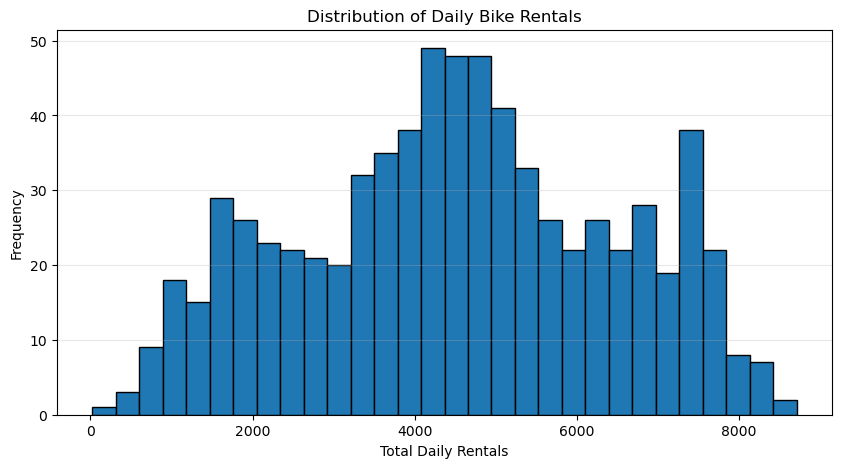

In [26]:
# Daily Rental Count Distribution

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.hist(day_df["cnt"], bins=30, edgecolor="black")

plt.title("Distribution of Daily Bike Rentals")
plt.xlabel("Total Daily Rentals")
plt.ylabel("Frequency")

plt.grid(axis="y", alpha=0.3)
plt.show()

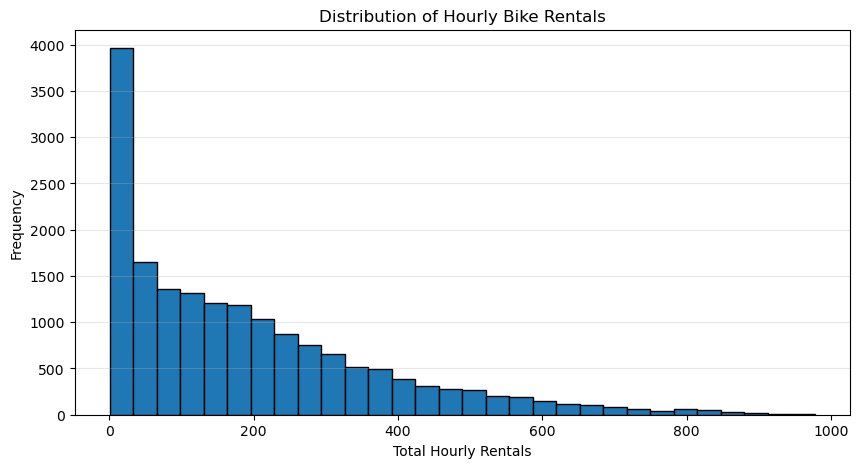

In [27]:
# Hourly Rental Count Distribution

plt.figure(figsize=(10, 5))

plt.hist(hour_df["cnt"], bins=30, edgecolor="black")

plt.title("Distribution of Hourly Bike Rentals")
plt.xlabel("Total Hourly Rentals")
plt.ylabel("Frequency")

plt.grid(axis="y", alpha=0.3)
plt.show()

In [28]:
# Statistical Summary of Target Variable

print("DAILY RENTAL COUNT")
display(day_df["cnt"].describe())

print("\nHOURLY RENTAL COUNT")
display(hour_df["cnt"].describe())

DAILY RENTAL COUNT


count     731.000000
mean     4504.348837
std      1937.211452
min        22.000000
25%      3152.000000
50%      4548.000000
75%      5956.000000
max      8714.000000
Name: cnt, dtype: float64


HOURLY RENTAL COUNT


count    17379.000000
mean       189.463088
std        181.387599
min          1.000000
25%         40.000000
50%        142.000000
75%        281.000000
max        977.000000
Name: cnt, dtype: float64

### Findings – Distribution of Total Bike Rentals

The statistical analysis of the target variable `cnt` revealed the following:

**Daily Dataset:**
- Average daily rentals: 4,504.
- Median daily rentals: 4,548.
- Standard deviation: 1,937.
- Minimum rentals: 22.
- Maximum rentals: 8,714.

The mean and median are relatively close, indicating that the daily rental distribution is not strongly skewed based on these statistics.

**Hourly Dataset:**
- Average hourly rentals: 189.
- Median hourly rentals: 142.
- Standard deviation: 181.
- Minimum rentals: 1.
- Maximum rentals: 977.

The mean being higher than the median suggests a possible right-skewed distribution, with certain hours experiencing considerably higher rental demand.

**Business Insight:**

Bike rental demand varies considerably across both days and hours. Understanding these variations will help identify demand patterns and develop more reliable rental prediction models.

### Visual Analysis – Distribution of Bike Rentals

**Daily Rental Distribution:**

The daily rental histogram shows that most observations are concentrated around 3,500–5,500 rentals. The distribution has a broad central peak, with relatively fewer observations at the extreme ends.

The distribution is not perfectly symmetrical and shows some irregularities, indicating variations in daily demand.

**Hourly Rental Distribution:**

The hourly rental histogram displays a strongly right-skewed distribution. Most observations have relatively low rental counts, while fewer observations have substantially higher rental counts.

The long right tail indicates that certain hours experience significantly greater rental demand than others.

**Business Insights:**

1. Daily rental demand is distributed across a broad range of values.
2. Hourly rental demand varies substantially throughout the day.
3. High-demand hours may require additional bike availability and operational planning.
4. The hourly target variable may benefit from transformation or robust modelling techniques if its skewness affects model performance. This will be evaluated during preprocessing and model building.

**Overall Conclusion:**

Daily and hourly rental counts exhibit different distribution patterns. These differences highlight the importance of analysing seasonal, weather-related, calendar-based, and hourly demand factors before developing predictive models.

In [30]:
# Average Bike Rentals by Season

season_demand = (
    day_df.groupby("season")["cnt"]
    .mean()
    .reset_index()
)

season_demand["season_name"] = season_demand["season"].map({
    1: "Spring",
    2: "Summer",
    3: "Fall",
    4: "Winter"
})

display(season_demand)

,season,cnt,season_name
0,1,2604.132597,Spring
1,2,4992.331522,Summer
2,3,5644.303191,Fall
3,4,4728.162921,Winter


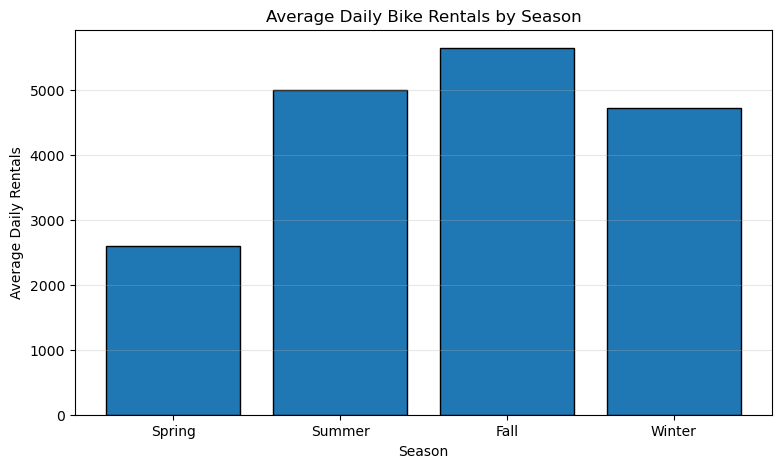

In [31]:
# Seasonal Rental Demand Visualization

plt.figure(figsize=(9, 5))

plt.bar(
    season_demand["season_name"],
    season_demand["cnt"],
    edgecolor="black"
)

plt.title("Average Daily Bike Rentals by Season")
plt.xlabel("Season")
plt.ylabel("Average Daily Rentals")

plt.grid(axis="y", alpha=0.3)
plt.show()

### Findings – Seasonal Bike Rental Demand

The seasonal analysis reveals significant differences in average daily bike rental demand.

- Fall records the highest average demand, with approximately 5,644 rentals per day.
- Summer follows with approximately 4,992 rentals.
- Winter records approximately 4,728 rentals.
- Spring has the lowest average demand, with approximately 2,604 rentals.

**Business Insights:**

1. Bike rental demand is strongly associated with seasonal variations.
2. Fall represents the period of highest average rental activity.
3. Spring experiences considerably lower rental demand.
4. The business should consider seasonal demand when planning fleet availability, maintenance, and resource allocation.

**Conclusion:**

Season is an important variable to investigate when predicting bike rental demand. The substantial difference between seasonal averages suggests that seasonal information may improve predictive model performance.

In [32]:
# Average Bike Rentals by Month

monthly_demand = (
    day_df.groupby("mnth")["cnt"]
    .mean()
    .reset_index()
)

month_names = {
    1: "January", 2: "February", 3: "March",
    4: "April", 5: "May", 6: "June",
    7: "July", 8: "August", 9: "September",
    10: "October", 11: "November", 12: "December"
}

monthly_demand["month_name"] = monthly_demand["mnth"].map(month_names)

display(monthly_demand)

,mnth,cnt,month_name
0,1,2176.338710,January
1,2,2655.298246,February
2,3,3692.258065,March
3,4,4484.900000,April
4,5,5349.774194,May
5,6,5772.366667,June
6,7,5563.677419,July
7,8,5664.419355,August
8,9,5766.516667,September
9,10,5199.225806,October


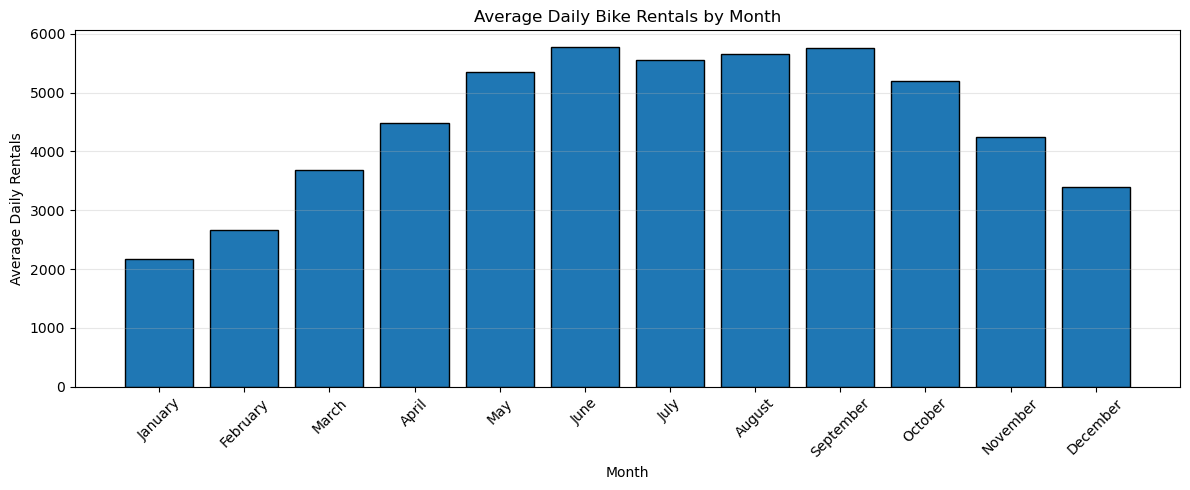

In [33]:
# Monthly Rental Demand Visualization

plt.figure(figsize=(12, 5))

plt.bar(
    monthly_demand["month_name"],
    monthly_demand["cnt"],
    edgecolor="black"
)

plt.title("Average Daily Bike Rentals by Month")
plt.xlabel("Month")
plt.ylabel("Average Daily Rentals")

plt.xticks(rotation=45)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

### Findings – Monthly Bike Rental Demand

Monthly analysis was performed using the average daily rental count for each month.

The results reveal the following patterns:

- June records the highest average daily rentals at approximately 5,772.
- September follows closely with approximately 5,767 rentals.
- January records the lowest average daily rentals at approximately 2,176.
- Demand increases considerably from January through June.
- Rental activity remains relatively high between May and October.
- Demand decreases during November and December.

**Business Insights:**

1. Bike rental demand follows a noticeable monthly pattern.
2. Fleet availability should be planned according to expected monthly demand.
3. Maintenance activities and inventory planning could be scheduled during comparatively low-demand periods.
4. Monthly information may provide useful predictive features for forecasting rental demand.

**Conclusion:**

Month is an important variable to investigate when predicting bike rental demand. The observed variations indicate that rental activity is influenced by the time of year.

In [34]:
# Average Bike Rentals by Weather Condition

weather_demand = (
    day_df.groupby("weathersit")["cnt"]
    .agg(["mean", "median", "count"])
    .reset_index()
)

weather_names = {
    1: "Clear",
    2: "Mist / Cloudy",
    3: "Light Rain / Snow",
    4: "Heavy Rain / Snow"
}

weather_demand["weather_name"] = (
    weather_demand["weathersit"].map(weather_names)
)

display(weather_demand)

,weathersit,mean,median,count,weather_name
0,1,4876.786177,4844.0,463,Clear
1,2,4035.862348,4040.0,247,Mist / Cloudy
2,3,1803.285714,1817.0,21,Light Rain / Snow


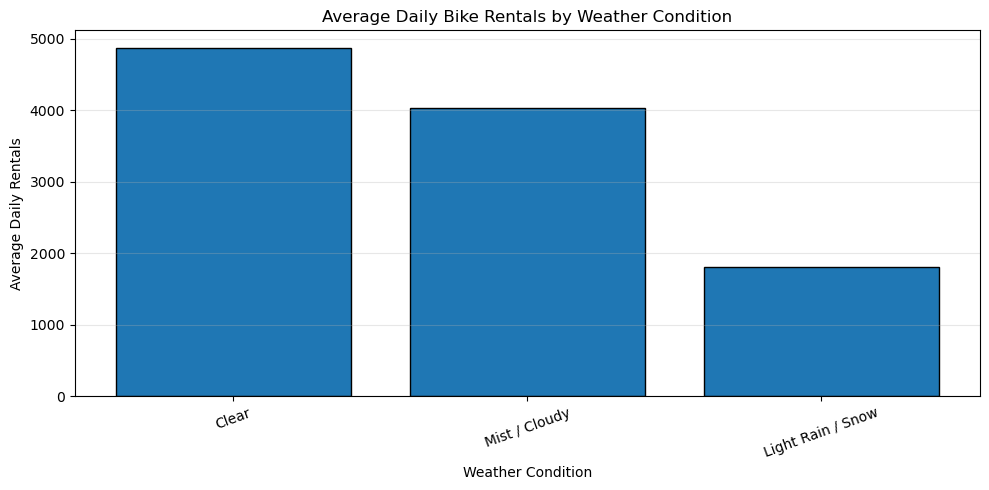

In [35]:
# Weather Impact Visualization

plt.figure(figsize=(10, 5))

plt.bar(
    weather_demand["weather_name"],
    weather_demand["mean"],
    edgecolor="black"
)

plt.title("Average Daily Bike Rentals by Weather Condition")
plt.xlabel("Weather Condition")
plt.ylabel("Average Daily Rentals")

plt.xticks(rotation=20)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [36]:
# Working Day vs Non-Working Day Analysis

workingday_demand = (
    day_df.groupby("workingday")["cnt"]
    .agg(["mean", "median", "count"])
    .reset_index()
)

workingday_demand["day_type"] = (
    workingday_demand["workingday"]
    .map({0: "Non-Working Day", 1: "Working Day"})
)

display(workingday_demand)

,workingday,mean,median,count,day_type
0,0,4330.168831,4459.0,231,Non-Working Day
1,1,4584.820000,4582.0,500,Working Day


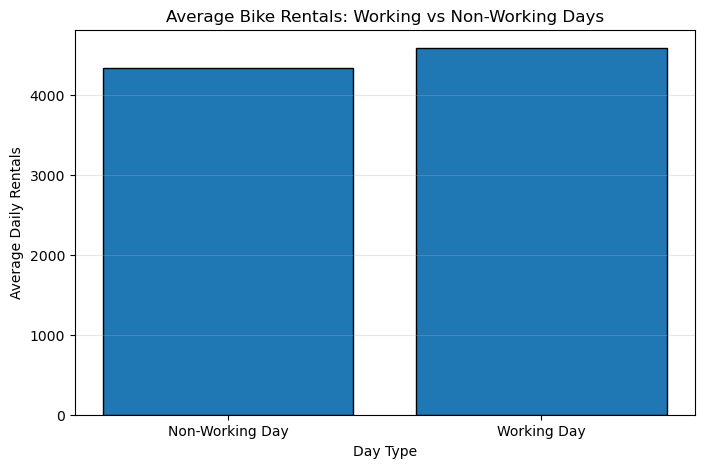

In [37]:
plt.figure(figsize=(8, 5))

plt.bar(
    workingday_demand["day_type"],
    workingday_demand["mean"],
    edgecolor="black"
)

plt.title("Average Bike Rentals: Working vs Non-Working Days")
plt.xlabel("Day Type")
plt.ylabel("Average Daily Rentals")

plt.grid(axis="y", alpha=0.3)
plt.show()

In [38]:
# Holiday vs Non-Holiday Demand

holiday_demand = (
    day_df.groupby("holiday")["cnt"]
    .agg(["mean", "median", "count"])
    .reset_index()
)

holiday_demand["day_type"] = (
    holiday_demand["holiday"]
    .map({0: "Non-Holiday", 1: "Holiday"})
)

display(holiday_demand)

,holiday,mean,median,count,day_type
0,0,4527.104225,4558.0,710,Non-Holiday
1,1,3735.000000,3351.0,21,Holiday


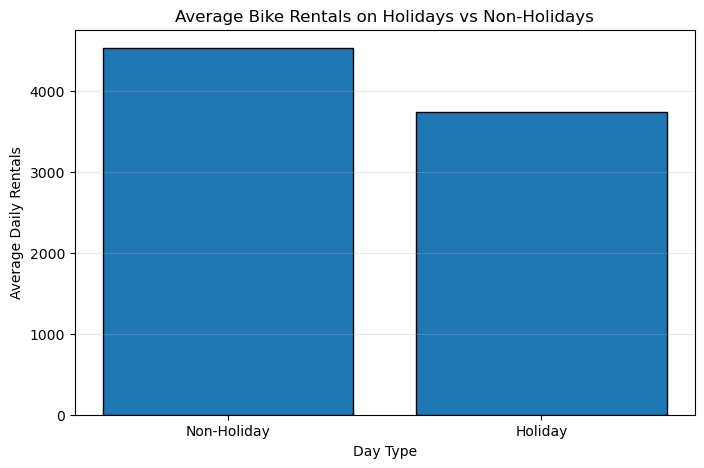

In [39]:
plt.figure(figsize=(8, 5))

plt.bar(
    holiday_demand["day_type"],
    holiday_demand["mean"],
    edgecolor="black"
)

plt.title("Average Bike Rentals on Holidays vs Non-Holidays")
plt.xlabel("Day Type")
plt.ylabel("Average Daily Rentals")

plt.grid(axis="y", alpha=0.3)
plt.show()

In [40]:
# Average Bike Rentals by Weekday

weekday_demand = (
    day_df.groupby("weekday")["cnt"]
    .agg(["mean", "median", "count"])
    .reset_index()
)

weekday_names = {
    0: "Sunday",
    1: "Monday",
    2: "Tuesday",
    3: "Wednesday",
    4: "Thursday",
    5: "Friday",
    6: "Saturday"
}

weekday_demand["weekday_name"] = (
    weekday_demand["weekday"].map(weekday_names)
)

display(weekday_demand)

,weekday,mean,median,count,weekday_name
0,0,4228.828571,4334.0,105,Sunday
1,1,4338.123810,4359.0,105,Monday
2,2,4510.663462,4576.5,104,Tuesday
3,3,4548.538462,4642.5,104,Wednesday
4,4,4667.259615,4721.0,104,Thursday
5,5,4690.288462,4601.5,104,Friday
6,6,4550.542857,4521.0,105,Saturday


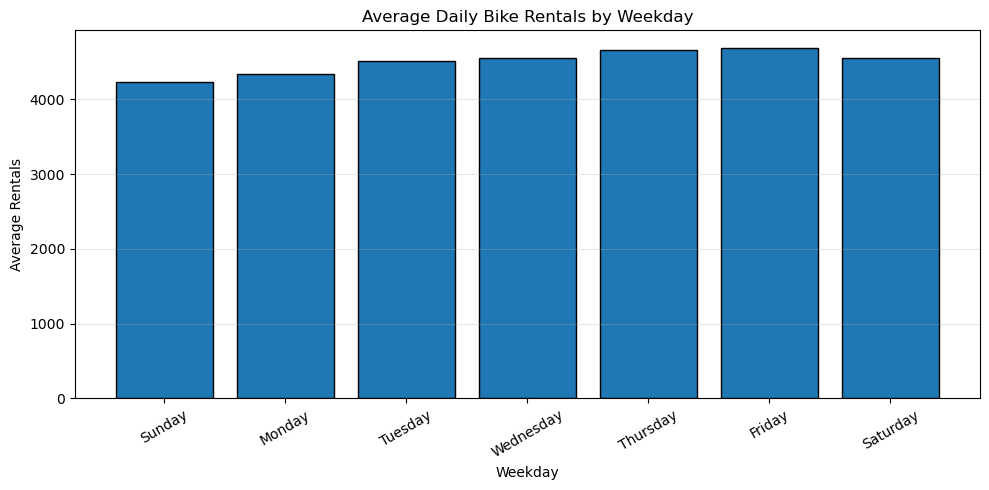

In [41]:
plt.figure(figsize=(10, 5))

plt.bar(
    weekday_demand["weekday_name"],
    weekday_demand["mean"],
    edgecolor="black"
)

plt.title("Average Daily Bike Rentals by Weekday")
plt.xlabel("Weekday")
plt.ylabel("Average Rentals")

plt.xticks(rotation=30)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [42]:
# Average Bike Rentals by Hour

hourly_demand = (
    hour_df.groupby("hr")["cnt"]
    .agg(["mean", "median", "count"])
    .reset_index()
)

display(hourly_demand)

,hr,mean,median,count
0,0,53.898072,40.0,726
1,1,33.375691,20.0,724
2,2,22.869930,11.0,715
3,3,11.727403,6.0,697
4,4,6.352941,6.0,697
5,5,19.889819,19.0,717
6,6,76.044138,76.0,725
7,7,212.064649,208.0,727
8,8,359.011004,385.0,727
9,9,219.309491,216.0,727


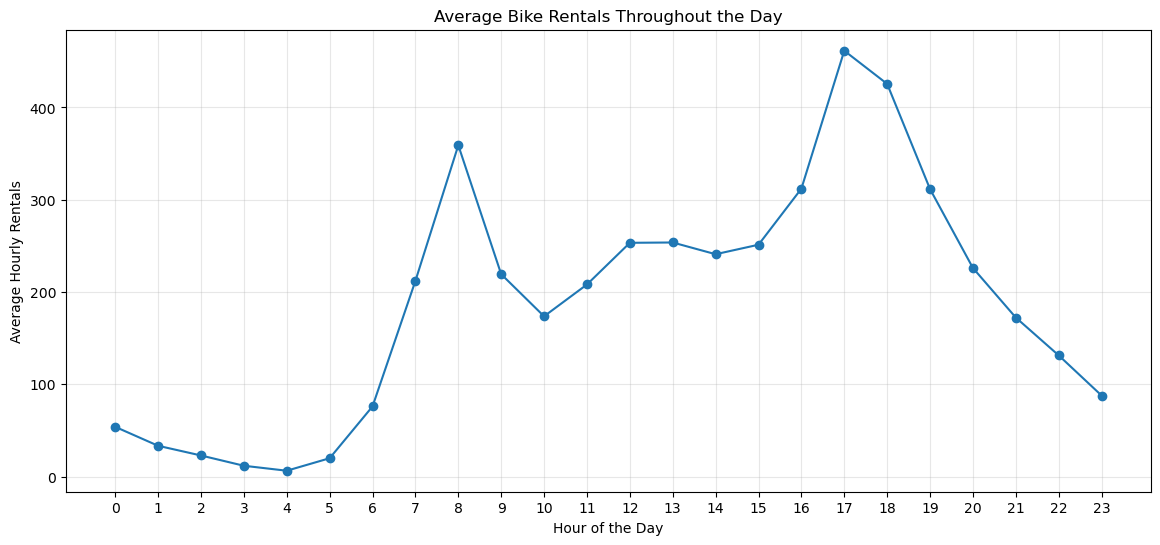

In [43]:
plt.figure(figsize=(14, 6))

plt.plot(
    hourly_demand["hr"],
    hourly_demand["mean"],
    marker="o"
)

plt.title("Average Bike Rentals Throughout the Day")
plt.xlabel("Hour of the Day")
plt.ylabel("Average Hourly Rentals")

plt.xticks(range(0, 24))
plt.grid(alpha=0.3)
plt.show()

In [44]:
# Create Weekend Feature

hour_df["day_type"] = hour_df["weekday"].apply(
    lambda x: "Weekend" if x in [0, 6] else "Weekday"
)

hourly_daytype = (
    hour_df.groupby(["hr", "day_type"])["cnt"]
    .mean()
    .reset_index()
)

display(hourly_daytype)

,hr,day_type,cnt
0,0,Weekday,37.626692
1,0,Weekend,94.148325
2,1,Weekday,17.464078
3,1,Weekend,72.583732
4,2,Weekday,9.377953
5,2,Weekend,55.980676
6,3,Weekday,5.188525
7,3,Weekend,26.995215
8,4,Weekday,5.446939
9,4,Weekend,8.497585


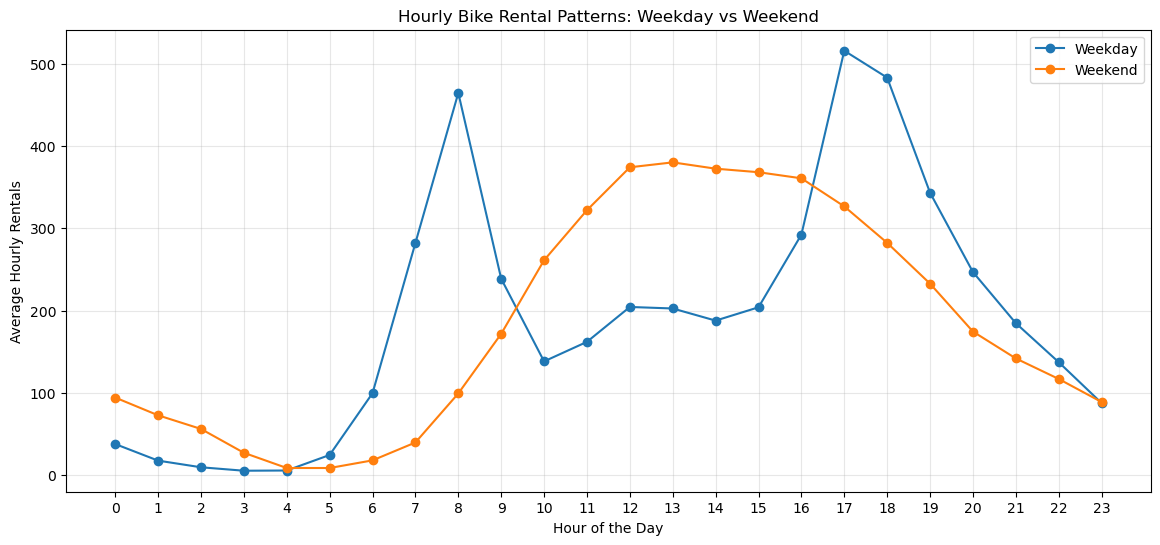

In [45]:
plt.figure(figsize=(14, 6))

for day_type in ["Weekday", "Weekend"]:

    temp_df = hourly_daytype[
        hourly_daytype["day_type"] == day_type
    ]

    plt.plot(
        temp_df["hr"],
        temp_df["cnt"],
        marker="o",
        label=day_type
    )

plt.title("Hourly Bike Rental Patterns: Weekday vs Weekend")
plt.xlabel("Hour of the Day")
plt.ylabel("Average Hourly Rentals")

plt.xticks(range(0, 24))
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [46]:
# Correlation Analysis

correlation_columns = [
    "season",
    "mnth",
    "holiday",
    "weekday",
    "workingday",
    "weathersit",
    "temp",
    "atemp",
    "hum",
    "windspeed",
    "casual",
    "registered",
    "cnt"
]

correlation_matrix = day_df[correlation_columns].corr()

display(correlation_matrix)

,season,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
season,1.000000,0.831440,-0.010537,-0.003080,0.012485,0.019211,0.334315,0.342876,0.205445,-0.229046,0.210399,0.411623,0.406100
mnth,0.831440,1.000000,0.019191,0.009509,-0.005901,0.043528,0.220205,0.227459,0.222204,-0.207502,0.123006,0.293488,0.279977
holiday,-0.010537,0.019191,1.000000,-0.101960,-0.253023,-0.034627,-0.028556,-0.032507,-0.015937,0.006292,0.054274,-0.108745,-0.068348
weekday,-0.003080,0.009509,-0.101960,1.000000,0.035790,0.031087,-0.000170,-0.007537,-0.052232,0.014282,0.059923,0.057367,0.067443
workingday,0.012485,-0.005901,-0.253023,0.035790,1.000000,0.061200,0.052660,0.052182,0.024327,-0.018796,-0.518044,0.303907,0.061156
weathersit,0.019211,0.043528,-0.034627,0.031087,0.061200,1.000000,-0.120602,-0.121583,0.591045,0.039511,-0.247353,-0.260388,-0.297391
temp,0.334315,0.220205,-0.028556,-0.000170,0.052660,-0.120602,1.000000,0.991702,0.126963,-0.157944,0.543285,0.540012,0.627494
atemp,0.342876,0.227459,-0.032507,-0.007537,0.052182,-0.121583,0.991702,1.000000,0.139988,-0.183643,0.543864,0.544192,0.631066
hum,0.205445,0.222204,-0.015937,-0.052232,0.024327,0.591045,0.126963,0.139988,1.000000,-0.248489,-0.077008,-0.091089,-0.100659
windspeed,-0.229046,-0.207502,0.006292,0.014282,-0.018796,0.039511,-0.157944,-0.183643,-0.248489,1.000000,-0.167613,-0.217449,-0.234545


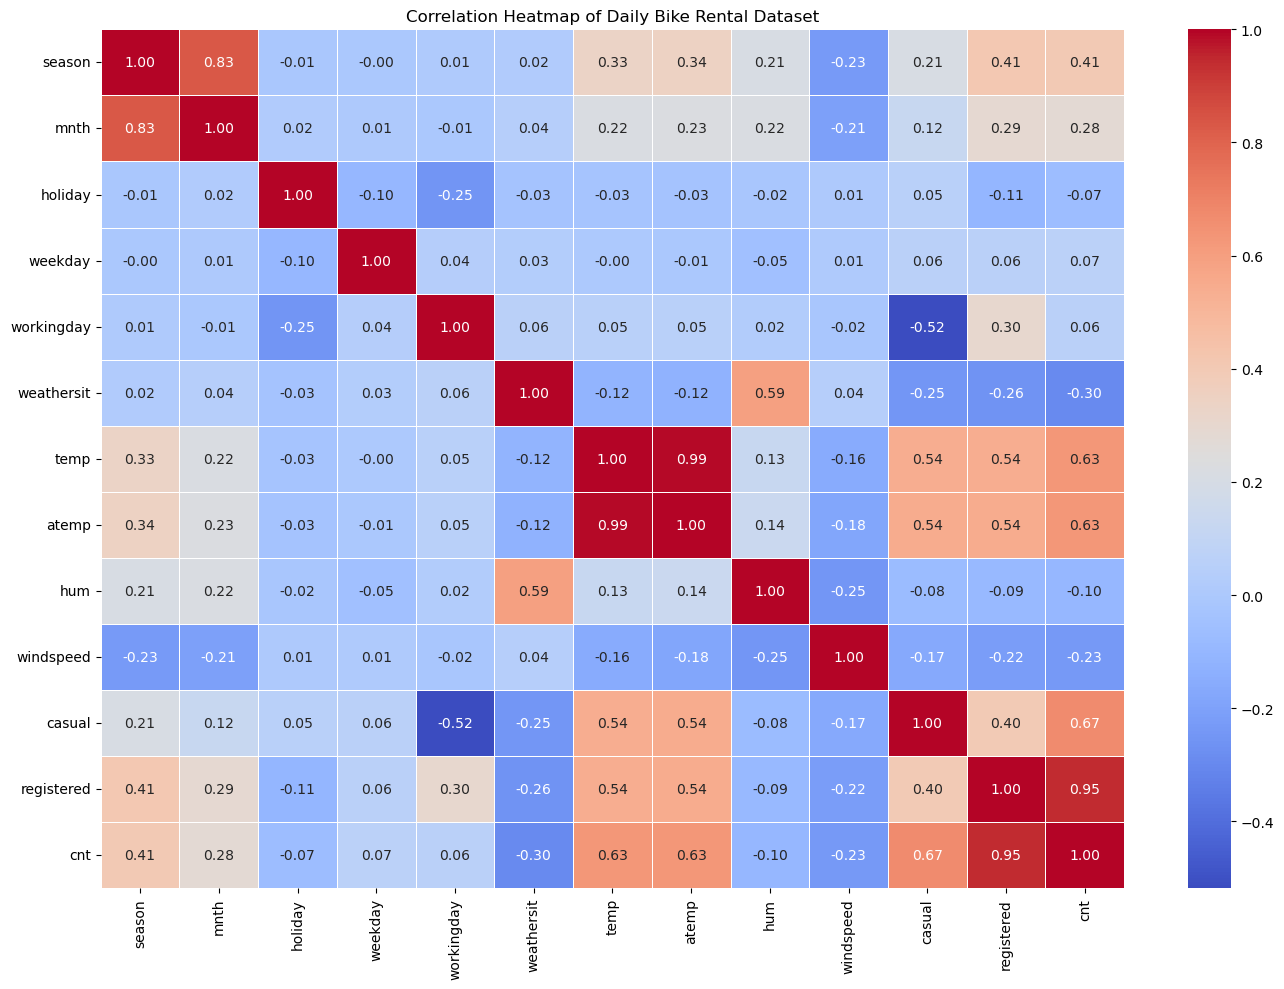

In [47]:
import seaborn as sns

plt.figure(figsize=(14, 10))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Heatmap of Daily Bike Rental Dataset")
plt.tight_layout()
plt.show()

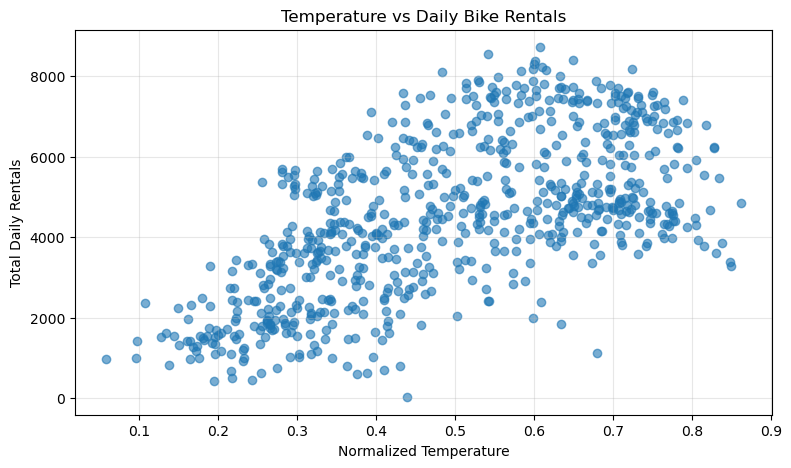

In [48]:
# Temperature vs Daily Bike Rentals

plt.figure(figsize=(9, 5))

plt.scatter(
    day_df["temp"],
    day_df["cnt"],
    alpha=0.6
)

plt.title("Temperature vs Daily Bike Rentals")
plt.xlabel("Normalized Temperature")
plt.ylabel("Total Daily Rentals")

plt.grid(alpha=0.3)
plt.show()

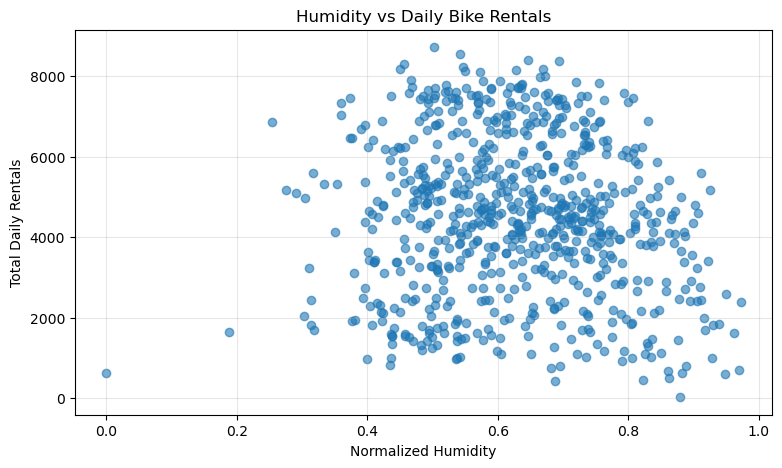

In [49]:
# Humidity vs Daily Bike Rentals

plt.figure(figsize=(9, 5))

plt.scatter(
    day_df["hum"],
    day_df["cnt"],
    alpha=0.6
)

plt.title("Humidity vs Daily Bike Rentals")
plt.xlabel("Normalized Humidity")
plt.ylabel("Total Daily Rentals")

plt.grid(alpha=0.3)
plt.show()

In [50]:
# Clean Weekday vs Weekend Hourly Summary

hourly_comparison = hourly_daytype.pivot(
    index="hr",
    columns="day_type",
    values="cnt"
).reset_index()

display(hourly_comparison.round(2))

day_type,hr,Weekday,Weekend
0,0,37.63,94.15
1,1,17.46,72.58
2,2,9.38,55.98
3,3,5.19,27.00
4,4,5.45,8.50
5,5,24.33,8.49
6,6,99.49,17.78
7,7,282.15,39.53
8,8,464.56,99.17
9,9,238.66,171.67


## Findings – Categorical and Multivariate Analysis

### 1. Working Day Analysis

Working days record approximately 4,585 average daily rentals, compared with approximately 4,330 on non-working days.

This indicates slightly higher rental demand on working days, potentially reflecting commuting and regular weekday activities.

### 2. Holiday Analysis

Non-holidays record approximately 4,527 average daily rentals, while holidays record approximately 3,735.

The lower holiday average suggests a possible reduction in rental demand during holidays. However, only 21 holiday observations are available, so this finding should be interpreted cautiously.

### 3. Weekday Analysis

Friday records the highest average daily rental demand, at approximately 4,690 rentals. Sunday records the lowest, at approximately 4,229 rentals.

Rental demand varies across the week, with relatively higher activity towards the end of the working week.

### 4. Hourly Demand Analysis

Hourly analysis identifies significant variations throughout the day.

- The highest average demand occurs at 17:00, with approximately 461 rentals.
- 18:00 records approximately 426 rentals.
- 08:00 records approximately 359 rentals.
- The lowest demand occurs at 04:00, with approximately 6 rentals.

The results indicate prominent morning and evening demand peaks.

### 5. Weekday vs Weekend Hourly Patterns

Weekdays show stronger morning and evening peaks, while weekends demonstrate relatively greater demand during midday and afternoon hours.

This suggests that commuting-related demand may influence weekday rental patterns.

### 6. Correlation Analysis

The correlation analysis identifies several relationships with total rental demand:

- Temperature has a positive correlation of approximately 0.627.
- Feeling temperature has a positive correlation of approximately 0.631.
- Weather situation has a negative correlation of approximately -0.297.
- Windspeed has a negative correlation of approximately -0.235.
- Humidity has a negative correlation of approximately -0.101.

Registered and casual rentals have strong correlations with total rentals because they are components of the target variable.

**Important Modelling Consideration:**

The variables `casual` and `registered` will be excluded from the predictor features because:

`cnt = casual + registered`

Using these variables to predict `cnt` would introduce target leakage.

### Overall Conclusion

The EDA indicates that bike rental demand is influenced by seasonal, monthly, weather-related, calendar-based, and hourly patterns.

Temperature, weather conditions, and time-related features appear particularly relevant for further investigation during predictive modelling.

### Findings – Weekday vs Weekend Hourly Demand

The hourly demand comparison reveals distinct rental patterns between weekdays and weekends.

**Weekday Patterns:**

- The morning peak occurs at 08:00, with approximately 465 average rentals.
- The evening peak occurs at 17:00, with approximately 516 average rentals.
- Demand is particularly high during typical commuting hours.

**Weekend Patterns:**

- Weekend demand increases during the morning and reaches its highest level at 13:00, with approximately 380 average rentals.
- Rental activity remains relatively high between 12:00 and 16:00.
- Weekend demand is more distributed throughout the afternoon.

**Business Insights:**

1. Weekday demand is strongly concentrated around morning and evening commuting periods.
2. Weekend demand is comparatively stronger during midday and afternoon hours.
3. Fleet allocation should consider different weekday and weekend demand patterns.
4. Hour of the day and day type may be useful predictive features.

**Conclusion:**

Weekday and weekend rental patterns differ considerably. Including both hourly and calendar-related information may improve bike rental demand forecasting.

# 6. Statistical Analysis

## 6.1 Objective

The objective of statistical analysis is to examine the numerical characteristics, distributions, variability, and relationships within the bike rental datasets.

This section will investigate:

1. Descriptive statistics of numerical variables.
2. Skewness and kurtosis of rental demand.
3. Statistical relationships between environmental variables and rental demand.
4. Differences in rental demand across selected categories.
5. The statistical relevance of important variables for predictive modelling.

In [51]:
# Descriptive Statistics - Daily Dataset

daily_statistics = day_df.describe().T

display(daily_statistics.round(3))

,count,mean,std,min,25%,50%,75%,max
instant,731.0,366.000,211.166,1.000,183.500,366.000,548.500,731.000
season,731.0,2.497,1.111,1.000,2.000,3.000,3.000,4.000
yr,731.0,0.501,0.500,0.000,0.000,1.000,1.000,1.000
mnth,731.0,6.520,3.452,1.000,4.000,7.000,10.000,12.000
holiday,731.0,0.029,0.167,0.000,0.000,0.000,0.000,1.000
weekday,731.0,2.997,2.005,0.000,1.000,3.000,5.000,6.000
workingday,731.0,0.684,0.465,0.000,0.000,1.000,1.000,1.000
weathersit,731.0,1.395,0.545,1.000,1.000,1.000,2.000,3.000
temp,731.0,0.495,0.183,0.059,0.337,0.498,0.655,0.862
atemp,731.0,0.474,0.163,0.079,0.338,0.487,0.609,0.841


In [52]:
# Descriptive Statistics - Hourly Dataset

hourly_statistics = hour_df.describe().T

display(hourly_statistics.round(3))

,count,mean,std,min,25%,50%,75%,max
instant,17379.0,8690.000,5017.029,1.00,4345.500,8690.000,13034.500,17379.000
season,17379.0,2.502,1.107,1.00,2.000,3.000,3.000,4.000
yr,17379.0,0.503,0.500,0.00,0.000,1.000,1.000,1.000
mnth,17379.0,6.538,3.439,1.00,4.000,7.000,10.000,12.000
hr,17379.0,11.547,6.914,0.00,6.000,12.000,18.000,23.000
holiday,17379.0,0.029,0.167,0.00,0.000,0.000,0.000,1.000
weekday,17379.0,3.004,2.006,0.00,1.000,3.000,5.000,6.000
workingday,17379.0,0.683,0.465,0.00,0.000,1.000,1.000,1.000
weathersit,17379.0,1.425,0.639,1.00,1.000,1.000,2.000,4.000
temp,17379.0,0.497,0.193,0.02,0.340,0.500,0.660,1.000


In [53]:
# Descriptive Statistics of Important Variables

important_columns = [
    "temp",
    "atemp",
    "hum",
    "windspeed",
    "casual",
    "registered",
    "cnt"
]

print("DAILY DATASET")
display(day_df[important_columns].describe().T.round(3))

print("\nHOURLY DATASET")
display(hour_df[important_columns].describe().T.round(3))

DAILY DATASET


,count,mean,std,min,25%,50%,75%,max
temp,731.0,0.495,0.183,0.059,0.337,0.498,0.655,0.862
atemp,731.0,0.474,0.163,0.079,0.338,0.487,0.609,0.841
hum,731.0,0.628,0.142,0.000,0.520,0.627,0.730,0.972
windspeed,731.0,0.190,0.077,0.022,0.135,0.181,0.233,0.507
casual,731.0,848.176,686.622,2.000,315.500,713.000,1096.000,3410.000
registered,731.0,3656.172,1560.256,20.000,2497.000,3662.000,4776.500,6946.000
cnt,731.0,4504.349,1937.211,22.000,3152.000,4548.000,5956.000,8714.000



HOURLY DATASET


,count,mean,std,min,25%,50%,75%,max
temp,17379.0,0.497,0.193,0.02,0.340,0.500,0.660,1.000
atemp,17379.0,0.476,0.172,0.00,0.333,0.485,0.621,1.000
hum,17379.0,0.627,0.193,0.00,0.480,0.630,0.780,1.000
windspeed,17379.0,0.190,0.122,0.00,0.104,0.194,0.254,0.851
casual,17379.0,35.676,49.305,0.00,4.000,17.000,48.000,367.000
registered,17379.0,153.787,151.357,0.00,34.000,115.000,220.000,886.000
cnt,17379.0,189.463,181.388,1.00,40.000,142.000,281.000,977.000


## Findings – Descriptive Statistical Analysis

Descriptive statistics were calculated for both daily and hourly bike rental datasets to understand the distribution, central tendency, and variability of numerical variables.

### Daily Dataset

- Average daily rentals are approximately 4,504.
- Standard deviation of daily rentals is approximately 1,937.
- Registered users contribute an average of approximately 3,656 rentals per day.
- Casual users contribute an average of approximately 848 rentals per day.
- Normalized temperature has an average value of 0.495.
- Normalized humidity has an average value of 0.628.

### Hourly Dataset

- Average hourly rentals are approximately 189.
- Standard deviation of hourly rentals is approximately 181.
- Registered users contribute an average of approximately 154 rentals per hour.
- Casual users contribute an average of approximately 36 rentals per hour.
- Temperature and humidity have average normalized values of approximately 0.497 and 0.627 respectively.

### Important Statistical Observations

1. Registered users account for a larger proportion of rentals than casual users.
2. Both daily and hourly rental counts exhibit considerable variability.
3. Temperature and feeling temperature are highly correlated.
4. The variables `casual` and `registered` directly determine the target variable `cnt` and must be excluded from predictive features.

**Conclusion:**

The descriptive statistical analysis highlights substantial variation in bike rental demand and identifies important relationships between numerical variables. These observations will guide subsequent statistical testing and feature selection.

In [54]:
# Skewness Analysis

skewness_daily = day_df[important_columns].skew()
skewness_hourly = hour_df[important_columns].skew()

print("DAILY DATASET SKEWNESS")
display(skewness_daily.to_frame("Skewness").round(3))

print("\nHOURLY DATASET SKEWNESS")
display(skewness_hourly.to_frame("Skewness").round(3))

DAILY DATASET SKEWNESS


,Skewness
temp,-0.055
atemp,-0.131
hum,-0.070
windspeed,0.677
casual,1.266
registered,0.044
cnt,-0.047



HOURLY DATASET SKEWNESS


,Skewness
temp,-0.006
atemp,-0.090
hum,-0.111
windspeed,0.575
casual,2.499
registered,1.558
cnt,1.277


In [55]:
# Kurtosis Analysis

kurtosis_daily = day_df[important_columns].kurtosis()
kurtosis_hourly = hour_df[important_columns].kurtosis()

print("DAILY DATASET KURTOSIS")
display(kurtosis_daily.to_frame("Kurtosis").round(3))

print("\nHOURLY DATASET KURTOSIS")
display(kurtosis_hourly.to_frame("Kurtosis").round(3))

DAILY DATASET KURTOSIS


,Kurtosis
temp,-1.119
atemp,-0.985
hum,-0.065
windspeed,0.411
casual,1.322
registered,-0.713
cnt,-0.812



HOURLY DATASET KURTOSIS


,Kurtosis
temp,-0.942
atemp,-0.845
hum,-0.826
windspeed,0.591
casual,7.571
registered,2.750
cnt,1.417


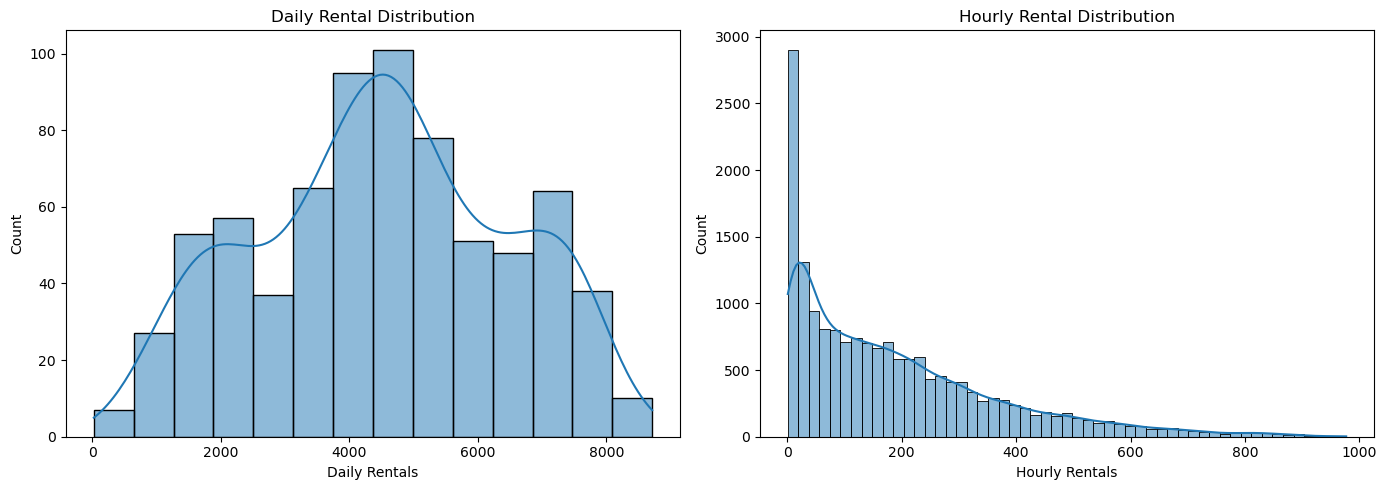

In [56]:
# Target Variable Distribution with KDE

import seaborn as sns

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(
    day_df["cnt"],
    kde=True,
    ax=axes[0]
)

axes[0].set_title("Daily Rental Distribution")
axes[0].set_xlabel("Daily Rentals")

sns.histplot(
    hour_df["cnt"],
    kde=True,
    ax=axes[1]
)

axes[1].set_title("Hourly Rental Distribution")
axes[1].set_xlabel("Hourly Rentals")

plt.tight_layout()
plt.show()

## Findings – Skewness and Kurtosis Analysis

Skewness and kurtosis were calculated to understand the shape, symmetry, and tail behaviour of numerical variables in both datasets.

### 1. Daily Dataset

- Daily rental count (`cnt`) has a skewness of approximately -0.047, indicating an approximately symmetrical distribution.
- Casual rentals have positive skewness of 1.266.
- Windspeed has positive skewness of 0.677.
- Daily rental count has kurtosis of -0.812, indicating lighter tails compared with a normal distribution.
- Casual rentals have positive kurtosis of 1.322.

### 2. Hourly Dataset

- Hourly rental count (`cnt`) has positive skewness of 1.277.
- Casual rentals have strong positive skewness of 2.499.
- Registered rentals have positive skewness of 1.558.
- Hourly rental count has positive kurtosis of 1.417.
- Casual rentals have particularly high kurtosis of 7.571.

### 3. Statistical Interpretation

The daily target variable is approximately symmetrical, while the hourly target variable is positively skewed.

The hourly dataset also shows heavier tails for rental counts and user categories, indicating occasional periods of unusually high demand.

### Conclusion

The distribution characteristics differ between daily and hourly rental data.

These findings will be considered during predictive modelling. Transformations will not be applied automatically; their usefulness will be evaluated based on model performance and residual behaviour.

In [57]:
# Separate Daily Rentals into Two Groups

workingday_rentals = day_df[
    day_df["workingday"] == 1
]["cnt"]

nonworkingday_rentals = day_df[
    day_df["workingday"] == 0
]["cnt"]

print("Working Day Observations:", len(workingday_rentals))
print("Non-Working Day Observations:", len(nonworkingday_rentals))

print("Working Day Mean:", workingday_rentals.mean())
print("Non-Working Day Mean:", nonworkingday_rentals.mean())

Working Day Observations: 500
Non-Working Day Observations: 231
Working Day Mean: 4584.82
Non-Working Day Mean: 4330.168831168831


In [58]:
# Independent Two-Sample Welch's T-Test

from scipy.stats import ttest_ind

t_statistic, p_value = ttest_ind(
    workingday_rentals,
    nonworkingday_rentals,
    equal_var=False
)

print("T-Statistic:", t_statistic)
print("P-Value:", p_value)

if p_value < 0.05:
    print("Result: Statistically significant difference.")
else:
    print("Result: No statistically significant difference.")

T-Statistic: 1.6013720686967898
P-Value: 0.11005737827017054
Result: No statistically significant difference.


### Statistical Test – Working Day vs Non-Working Day Demand

An independent two-sample Welch's t-test was conducted to investigate whether average daily bike rental demand differs significantly between working days and non-working days.

**Hypotheses:**

- Null Hypothesis (H₀): There is no statistically significant difference in average bike rentals between working days and non-working days.
- Alternative Hypothesis (H₁): There is a statistically significant difference in average bike rentals between the two groups.

**Results:**

- Working day mean: 4,584.82 rentals.
- Non-working day mean: 4,330.17 rentals.
- T-statistic: 1.6014.
- P-value: 0.1101.
- Significance level: 0.05.

**Decision:**

Since the p-value (0.1101) is greater than 0.05, the null hypothesis is not rejected.

**Conclusion:**

Although working days show higher average rental demand, the observed difference is not statistically significant at the 5% significance level. Therefore, there is insufficient statistical evidence to conclude that average rental demand differs between working and non-working days.

In [59]:
# Prepare Rental Groups by Weather Condition

weather_groups = [
    day_df.loc[day_df["weathersit"] == weather, "cnt"]
    for weather in sorted(day_df["weathersit"].unique())
]

for weather, group in zip(
    sorted(day_df["weathersit"].unique()),
    weather_groups
):
    print(
        f"Weather {weather}: "
        f"Observations = {len(group)}, "
        f"Mean = {group.mean():.2f}, "
        f"Median = {group.median():.2f}"
    )

Weather 1: Observations = 463, Mean = 4876.79, Median = 4844.00
Weather 2: Observations = 247, Mean = 4035.86, Median = 4040.00
Weather 3: Observations = 21, Mean = 1803.29, Median = 1817.00


In [60]:
# Kruskal-Wallis H-Test

from scipy.stats import kruskal

h_statistic, p_value = kruskal(*weather_groups)

print("H-Statistic:", h_statistic)
print("P-Value:", p_value)

if p_value < 0.05:
    print("Result: Significant difference in rental distributions across weather conditions.")
else:
    print("Result: No statistically significant difference detected.")

H-Statistic: 67.17520449165305
P-Value: 2.588747451005407e-15
Result: Significant difference in rental distributions across weather conditions.


### 6.5 Kruskal–Wallis H-Test: Rental Demand Across Weather Conditions

A Kruskal–Wallis H-test was conducted to examine whether daily bike rental distributions differ across weather conditions.

The test produced an H-statistic of 67.1752 and a p-value of 2.5887 × 10⁻¹⁵. Since the p-value is considerably lower than the significance level of 0.05, the null hypothesis was rejected.

The descriptive results indicate that clear weather recorded the highest average daily rentals (4,876.79), followed by misty or cloudy weather (4,035.86). Light rain or snow recorded the lowest average (1,803.29).

These results provide strong statistical evidence that weather conditions are associated with differences in bike rental demand. However, the third weather category contains only 21 observations, so its results should be interpreted cautiously.

The Kruskal–Wallis test identifies an overall difference but does not establish which specific weather categories differ significantly. Further pairwise testing would be required for that conclusion.

In [61]:
from scipy.stats import spearmanr

environmental_features = ["temp", "atemp", "hum", "windspeed"]

spearman_results = []

for feature in environmental_features:
    correlation, p_value = spearmanr(day_df[feature], day_df["cnt"])

    spearman_results.append({
        "Feature": feature,
        "Spearman Correlation": correlation,
        "P-Value": p_value,
        "Significant": "Yes" if p_value < 0.05 else "No"
    })

spearman_df = pd.DataFrame(spearman_results)

spearman_df

,Feature,Spearman Correlation,P-Value,Significant
0,temp,0.622034,1.674555e-79,Yes
1,atemp,0.622782,9.615484e-80,Yes
2,hum,-0.098126,7.933230e-03,Yes
3,windspeed,-0.217197,2.969427e-09,Yes


### 6.6 Spearman Correlation Analysis

Spearman rank correlation was performed to examine the relationships between environmental variables and daily bike rental demand.

The results revealed the following findings:

- Temperature showed a strong positive correlation with rental demand (0.6220).
- Feeling temperature also showed a strong positive correlation (0.6228).
- Humidity showed a very weak negative correlation (-0.0981).
- Windspeed showed a weak negative correlation (-0.2172).

All four relationships were statistically significant at the 5% significance level, as their p-values were below 0.05.

Temperature and feeling temperature appear to have the strongest positive associations with rental demand. Humidity and windspeed show negative associations, although their relationships are comparatively weak.

These findings suggest that environmental conditions are relevant factors for understanding bike rental demand. However, correlation does not establish causation.

Temperature and feeling temperature are also highly correlated with each other, so their potential multicollinearity should be considered during model development.

### 6.7 Statistical Analysis Summary

The statistical analysis provided additional evidence about the factors associated with bike rental demand.

The descriptive statistics showed considerable variation in rental counts. The daily rental target was approximately symmetrical, whereas hourly rental counts were positively skewed.

The Welch independent two-sample t-test found no statistically significant difference in average rentals between working and non-working days (p = 0.1101).

The Kruskal–Wallis test identified a statistically significant difference in rental distributions across weather conditions (p < 0.05).

Spearman correlation analysis identified strong positive associations between temperature variables and rental demand, along with weak negative associations for humidity and windspeed.

Overall, the analysis suggests that temperature and weather conditions are important variables to investigate during predictive modelling. Working-day status may still be useful as a predictive feature even though its average difference was not statistically significant in the hypothesis test.

The statistical findings will guide feature selection, preprocessing decisions and model development in the subsequent stages.

## 7. Data Cleaning

### 7.1 Objective

The objective of data cleaning is to prepare the daily bike rental dataset for predictive modelling by ensuring that the data is consistent, relevant and suitable for analysis.

The initial data quality assessment identified no missing values, duplicate records, invalid categorical values, negative numerical values or inconsistencies between the daily and hourly datasets.

The following cleaning decisions will be applied:

1. Create a separate copy of the daily dataset to preserve the original data.
2. Convert the date column into an appropriate datetime format.
3. Sort records chronologically.
4. Remove the `instant` column because it is an identifier rather than a meaningful predictive variable.
5. Exclude `casual` and `registered` from the modelling dataset because their sum directly determines the target variable `cnt`. Keeping them as predictors would cause target leakage.

The target variable `cnt` will be retained for prediction.

In [62]:
# Create a copy of the daily dataset

clean_df = day_df.copy()

# Convert date column to datetime format

clean_df["dteday"] = pd.to_datetime(clean_df["dteday"])

# Sort records chronologically

clean_df = clean_df.sort_values("dteday").reset_index(drop=True)

# Display dataset information

print("Dataset shape before cleaning:", clean_df.shape)

clean_df.head()

Dataset shape before cleaning: (731, 16)


,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,6,0,2,0.344167,0.363625,0.805833,0.160446,331,654,985
1,2,2011-01-02,1,0,1,0,0,0,2,0.363478,0.353739,0.696087,0.248539,131,670,801
2,3,2011-01-03,1,0,1,0,1,1,1,0.196364,0.189405,0.437273,0.248309,120,1229,1349
3,4,2011-01-04,1,0,1,0,2,1,1,0.200000,0.212122,0.590435,0.160296,108,1454,1562
4,5,2011-01-05,1,0,1,0,3,1,1,0.226957,0.229270,0.436957,0.186900,82,1518,1600


In [63]:
# Remove identifier and target leakage columns

clean_df = clean_df.drop(
    columns=["instant", "casual", "registered"]
)

# Check the updated dataset

print("Dataset shape after removing unnecessary columns:", clean_df.shape)

print("\nRemaining columns:")
print(clean_df.columns.tolist())

clean_df.head()

Dataset shape after removing unnecessary columns: (731, 13)

Remaining columns:
['dteday', 'season', 'yr', 'mnth', 'holiday', 'weekday', 'workingday', 'weathersit', 'temp', 'atemp', 'hum', 'windspeed', 'cnt']


,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,cnt
0,2011-01-01,1,0,1,0,6,0,2,0.344167,0.363625,0.805833,0.160446,985
1,2011-01-02,1,0,1,0,0,0,2,0.363478,0.353739,0.696087,0.248539,801
2,2011-01-03,1,0,1,0,1,1,1,0.196364,0.189405,0.437273,0.248309,1349
3,2011-01-04,1,0,1,0,2,1,1,0.200000,0.212122,0.590435,0.160296,1562
4,2011-01-05,1,0,1,0,3,1,1,0.226957,0.229270,0.436957,0.186900,1600


In [64]:
# Check missing values

print("Missing Values:")
print(clean_df.isnull().sum())

# Check duplicate records

print("\nDuplicate Rows:", clean_df.duplicated().sum())

# Check infinite values

print("\nInfinite Values:")
print(np.isinf(clean_df.select_dtypes(include=np.number)).sum().sum())

# Check target variable

print("\nTarget Variable Summary:")
print(clean_df["cnt"].describe())

# Check final dataset shape

print("\nFinal Dataset Shape:", clean_df.shape)

Missing Values:
dteday        0
season        0
yr            0
mnth          0
holiday       0
weekday       0
workingday    0
weathersit    0
temp          0
atemp         0
hum           0
windspeed     0
cnt           0
dtype: int64

Duplicate Rows: 0

Infinite Values:
0

Target Variable Summary:
count     731.000000
mean     4504.348837
std      1937.211452
min        22.000000
25%      3152.000000
50%      4548.000000
75%      5956.000000
max      8714.000000
Name: cnt, dtype: float64

Final Dataset Shape: (731, 13)


### 7.5 Data Cleaning Summary

The daily bike rental dataset was successfully cleaned and validated.

The original dataset contained 731 records and 16 columns. The identifier column `instant` and target leakage columns `casual` and `registered` were removed, resulting in a modelling dataset containing 731 records and 13 columns.

The final validation confirmed:

- No missing values.
- No duplicate records.
- No infinite numerical values.
- The target variable `cnt` was retained successfully.
- The chronological date sequence was preserved.

No additional record removal or missing-value treatment was required because the initial dataset had already passed the data quality assessment.

The cleaned dataset is now ready for feature engineering and preprocessing.

## 8. Feature Engineering

### 8.1 Objective

Feature engineering is performed to extract additional predictive information from the existing dataset.

The date column contains useful temporal information that may influence daily bike rental demand. Therefore, additional date-based features will be created to help machine learning models identify seasonal, monthly and weekly patterns.

The following features will be considered:

1. Year
2. Month
3. Day of the month
4. Day of the year
5. Weekend indicator

Existing calendar and environmental variables will also be retained where relevant.

Feature engineering will be performed without using information derived from the target variable.

In [65]:
# Extract date-based features

clean_df["year"] = clean_df["dteday"].dt.year

clean_df["month"] = clean_df["dteday"].dt.month

clean_df["day"] = clean_df["dteday"].dt.day

clean_df["dayofyear"] = clean_df["dteday"].dt.dayofyear

clean_df["is_weekend"] = (
    clean_df["weekday"].isin([0, 6]).astype(int)
)

# Display newly created features

clean_df[
    ["dteday", "year", "month", "day", "dayofyear",
     "weekday", "is_weekend", "cnt"]
].head(10)

,dteday,year,month,day,dayofyear,weekday,is_weekend,cnt
0,2011-01-01,2011,1,1,1,6,1,985
1,2011-01-02,2011,1,2,2,0,1,801
2,2011-01-03,2011,1,3,3,1,0,1349
3,2011-01-04,2011,1,4,4,2,0,1562
4,2011-01-05,2011,1,5,5,3,0,1600
5,2011-01-06,2011,1,6,6,4,0,1606
6,2011-01-07,2011,1,7,7,5,0,1510
7,2011-01-08,2011,1,8,8,6,1,959
8,2011-01-09,2011,1,9,9,0,1,822
9,2011-01-10,2011,1,10,10,1,0,1321


In [66]:
# Validate newly created features

print("Year values:")
print(sorted(clean_df["year"].unique()))

print("\nMonth range:")
print(clean_df["month"].min(), "to", clean_df["month"].max())

print("\nDay range:")
print(clean_df["day"].min(), "to", clean_df["day"].max())

print("\nDay of year range:")
print(clean_df["dayofyear"].min(), "to", clean_df["dayofyear"].max())

print("\nWeekend distribution:")
print(clean_df["is_weekend"].value_counts())

print("\nWeekend mapping check:")
print(
    (clean_df["is_weekend"] ==
     clean_df["weekday"].isin([0, 6]).astype(int)).all()
)

Year values:
[np.int32(2011), np.int32(2012)]

Month range:
1 to 12

Day range:
1 to 31

Day of year range:
1 to 366

Weekend distribution:
is_weekend
0    521
1    210
Name: count, dtype: int64

Weekend mapping check:
True


### 8.4 Feature Engineering Summary

Date-based feature engineering was successfully performed on the daily bike rental dataset.

The following features were extracted from the date column:

- `year`: Calendar year.
- `month`: Calendar month.
- `day`: Day of the month.
- `dayofyear`: Day number within the year.
- `is_weekend`: Binary indicator identifying Saturday and Sunday.

Validation confirmed that the extracted values were within their expected ranges and that the weekend indicator was correctly assigned.

The dataset now contains additional temporal information that may help predictive models identify seasonal and calendar-based patterns.

Some engineered features overlap with existing variables, such as `year` and `yr`, or `month` and `mnth`. These redundancies will be considered when selecting the final modelling features.

## 9. Data Preprocessing

### 9.1 Objective

Data preprocessing involves preparing the cleaned and engineered dataset in a format suitable for machine learning algorithms.

The following activities will be performed:

1. Separate the target variable from the independent variables.
2. Remove redundant and unsuitable features.
3. Identify numerical and categorical variables.
4. Handle categorical variables using appropriate encoding techniques.
5. Scale numerical features where required by the selected algorithms.

The target variable for this project is `cnt`, representing the total daily bike rental count.

The preprocessing pipeline will be designed to prevent data leakage by learning transformations only from the training data.

In [67]:
# Separate target variable

X = clean_df.drop(
    columns=[
        "cnt",
        "dteday",
        "yr",
        "mnth",
        "weekday"
    ]
)

y = clean_df["cnt"]

# Display features and target

print("Feature dataset shape:", X.shape)
print("Target dataset shape:", y.shape)

print("\nFeature columns:")
print(X.columns.tolist())

print("\nTarget variable:")
print(y.name)

Feature dataset shape: (731, 13)
Target dataset shape: (731,)

Feature columns:
['season', 'holiday', 'workingday', 'weathersit', 'temp', 'atemp', 'hum', 'windspeed', 'year', 'month', 'day', 'dayofyear', 'is_weekend']

Target variable:
cnt


In [68]:
# Separate target variable

y = clean_df["cnt"]

# Select independent variables

X = clean_df.drop(
    columns=[
        "cnt",
        "dteday",
        "yr",
        "mnth",
        "is_weekend"
    ]
)

# Display feature and target information

print("Feature dataset shape:", X.shape)
print("Target dataset shape:", y.shape)

print("\nSelected features:")
print(X.columns.tolist())

print("\nTarget variable:", y.name)

Feature dataset shape: (731, 13)
Target dataset shape: (731,)

Selected features:
['season', 'holiday', 'weekday', 'workingday', 'weathersit', 'temp', 'atemp', 'hum', 'windspeed', 'year', 'month', 'day', 'dayofyear']

Target variable: cnt


In [69]:
# Define categorical and numerical features

categorical_features = [
    "season",
    "holiday",
    "weekday",
    "workingday",
    "weathersit"
]

numerical_features = [
    "temp",
    "atemp",
    "hum",
    "windspeed",
    "year",
    "month",
    "day",
    "dayofyear"
]

# Display feature groups

print("Categorical Features:", categorical_features)
print("\nNumber of categorical features:", len(categorical_features))

print("\nNumerical Features:", numerical_features)
print("\nNumber of numerical features:", len(numerical_features))

print("\nTotal Features:", len(categorical_features) + len(numerical_features))

Categorical Features: ['season', 'holiday', 'weekday', 'workingday', 'weathersit']

Number of categorical features: 5

Numerical Features: ['temp', 'atemp', 'hum', 'windspeed', 'year', 'month', 'day', 'dayofyear']

Number of numerical features: 8

Total Features: 13


In [70]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline

In [71]:
# Numerical preprocessing

numerical_transformer = StandardScaler()

# Categorical preprocessing

categorical_transformer = OneHotEncoder(
    handle_unknown="ignore"
)

# Combine both preprocessing methods

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numerical_transformer, numerical_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

print("Preprocessing pipeline created successfully.")

Preprocessing pipeline created successfully.


## 10. Train-Test Split

### 10.1 Objective

The dataset will be divided into training and testing subsets to evaluate the predictive performance of machine learning models.

An 80:20 chronological split will be applied.

The first 80% of observations will be used for model training, while the remaining 20% will be reserved for testing.

Since the dataset represents daily rental demand over time, random shuffling will be avoided. A chronological split ensures that the models are trained on historical observations and evaluated on subsequent observations.

This approach provides a more realistic assessment of predictive performance on future rental demand.

# Define chronological split point

split_index = int(len(X) * 0.80)

# Split features

X_train = X.iloc[:split_index]
X_test = X.iloc[split_index:]

# Split target

y_train = y.iloc[:split_index]
y_test = y.iloc[split_index:]

# Display dataset shapes

print("Training Features:", X_train.shape)
print("Testing Features:", X_test.shape)

print("\nTraining Target:", y_train.shape)
print("Testing Target:", y_test.shape)

In [73]:
# Define chronological split point

split_index = int(len(X) * 0.80)

# Split features

X_train = X.iloc[:split_index]
X_test = X.iloc[split_index:]

# Split target

y_train = y.iloc[:split_index]
y_test = y.iloc[split_index:]

# Display dataset shapes

print("Training Features:", X_train.shape)
print("Testing Features:", X_test.shape)

print("\nTraining Target:", y_train.shape)
print("Testing Target:", y_test.shape)

Training Features: (584, 13)
Testing Features: (147, 13)

Training Target: (584,)
Testing Target: (147,)


In [74]:
# Check training and testing date ranges

print("Training Period:")
print(clean_df["dteday"].iloc[0], "to",
      clean_df["dteday"].iloc[split_index - 1])

print("\nTesting Period:")
print(clean_df["dteday"].iloc[split_index], "to",
      clean_df["dteday"].iloc[-1])

# Verify chronological order

print("\nTraining ends before testing starts:",
      clean_df["dteday"].iloc[split_index - 1] <
      clean_df["dteday"].iloc[split_index])

Training Period:
2011-01-01 00:00:00 to 2012-08-06 00:00:00

Testing Period:
2012-08-07 00:00:00 to 2012-12-31 00:00:00

Training ends before testing starts: True


### 10.4 Train-Test Split Summary

The daily bike rental dataset was divided into training and testing subsets using an 80:20 chronological split.

The training dataset contains 584 observations, covering 1 January 2011 to 6 August 2012.

The testing dataset contains 147 observations, covering 7 August 2012 to 31 December 2012.

Chronological validation confirmed that the training period ends before the testing period begins.

This approach preserves the temporal order of observations and provides a realistic evaluation of model performance on subsequent dates.

## 11. Model Building

### 11.1 Objective

The objective of model building is to develop machine learning regression models capable of predicting daily bike rental demand using environmental, seasonal and calendar-related features.

Multiple regression algorithms will be trained and evaluated to identify the most suitable approach for this prediction problem.

The following algorithms will be considered:

1. Linear Regression
2. Decision Tree Regressor
3. Random Forest Regressor
4. Gradient Boosting Regressor
5. K-Nearest Neighbors Regressor
6. Support Vector Regressor

A common preprocessing pipeline will be used where appropriate to ensure consistent data preparation and prevent information leakage.

Model performance will subsequently be compared using appropriate regression evaluation metrics.

In [75]:
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.svm import SVR

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

import numpy as np
import pandas as pd

In [76]:
models = {
    "Linear Regression": LinearRegression(),

    "Decision Tree": DecisionTreeRegressor(
        random_state=42
    ),

    "Random Forest": RandomForestRegressor(
        random_state=42
    ),

    "Gradient Boosting": GradientBoostingRegressor(
        random_state=42
    ),

    "KNN": KNeighborsRegressor(),

    "SVR": SVR()
}

print("Models initialized successfully.")

for name in models:
    print(name)

Models initialized successfully.
Linear Regression
Decision Tree
Random Forest
Gradient Boosting
KNN
SVR


In [77]:
# Dictionary to store trained models and results

trained_models = {}
results = []

# Train and evaluate each model

for name, model in models.items():

    # Create complete pipeline
    pipeline = Pipeline(
        steps=[
            ("preprocessor", preprocessor),
            ("model", model)
        ]
    )

    # Train model
    pipeline.fit(X_train, y_train)

    # Make predictions
    y_pred = pipeline.predict(X_test)

    # Calculate evaluation metrics
    mae = mean_absolute_error(y_test, y_pred)
    mse = mean_squared_error(y_test, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test, y_pred)

    # Store trained model
    trained_models[name] = pipeline

    # Store results
    results.append({
        "Model": name,
        "MAE": mae,
        "MSE": mse,
        "RMSE": rmse,
        "R2 Score": r2
    })

    print(f"{name} trained successfully.")

print("\nAll models trained successfully.")

Linear Regression trained successfully.
Decision Tree trained successfully.
Random Forest trained successfully.
Gradient Boosting trained successfully.
KNN trained successfully.
SVR trained successfully.

All models trained successfully.


In [78]:
# Create model comparison dataframe

initial_results = pd.DataFrame(results)

# Sort models by RMSE

initial_results = initial_results.sort_values(
    by="RMSE",
    ascending=True
).reset_index(drop=True)

initial_results

,Model,MAE,MSE,RMSE,R2 Score
0,Gradient Boosting,767.642449,8.985093e+05,947.897329,0.744320
1,Random Forest,895.637891,1.243358e+06,1115.059584,0.646190
2,Linear Regression,908.408726,1.419755e+06,1191.534871,0.595995
3,Decision Tree,1223.442177,2.338045e+06,1529.066546,0.334687
4,KNN,1361.874830,2.665480e+06,1632.629788,0.241512
5,SVR,2238.277891,6.269314e+06,2503.859824,-0.783994


### 11.6 Initial Model Evaluation

Six regression algorithms were trained and evaluated using the same chronological training and testing datasets.

The initial results showed that Gradient Boosting achieved the best performance, with an MAE of 767.64, RMSE of 947.90 and R² score of 0.7443.

Random Forest ranked second with an R² score of 0.6462, followed by Linear Regression with 0.5960.

Decision Tree and KNN showed comparatively weaker predictive performance. Support Vector Regression performed poorly, producing a negative R² score of -0.7840.

Based on the baseline evaluation, Gradient Boosting is the leading candidate for further optimization. Random Forest will also be considered for hyperparameter tuning.

These results represent initial model performance and do not establish the final production model.

## 12. Hyperparameter Tuning

### 12.1 Objective

Hyperparameter tuning will be performed to improve the predictive performance of the leading baseline models.

Based on the initial evaluation, Gradient Boosting and Random Forest have been selected as candidates for optimization.

TimeSeriesSplit cross-validation will be applied to the training dataset to preserve chronological ordering during model selection.

The final testing dataset will remain untouched during hyperparameter tuning to provide an unbiased final evaluation.

The models will be evaluated using negative mean absolute error as the cross-validation scoring metric.

In [79]:
from sklearn.model_selection import TimeSeriesSplit, GridSearchCV

In [80]:
# Configure time-series cross-validation

tscv = TimeSeriesSplit(n_splits=5)

print("Time-Series Cross-Validation configured.")
print("Number of splits:", tscv.get_n_splits())

Time-Series Cross-Validation configured.
Number of splits: 5


In [81]:
# Create Gradient Boosting pipeline

gb_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", GradientBoostingRegressor(random_state=42))
    ]
)

# Define hyperparameter search space

gb_param_grid = {
    "model__n_estimators": [100, 200, 300],
    "model__learning_rate": [0.03, 0.05, 0.1],
    "model__max_depth": [2, 3],
    "model__subsample": [0.8, 1.0]
}

print("Gradient Boosting tuning pipeline created.")
print("Total parameter combinations:",
      3 * 3 * 2 * 2)

Gradient Boosting tuning pipeline created.
Total parameter combinations: 36


In [82]:
# Configure GridSearchCV

gb_grid_search = GridSearchCV(
    estimator=gb_pipeline,
    param_grid=gb_param_grid,
    cv=tscv,
    scoring="neg_mean_absolute_error",
    n_jobs=-1,
    verbose=1
)

# Fit using training data only

gb_grid_search.fit(X_train, y_train)

# Display best parameters and score

print("\nBest Gradient Boosting Parameters:")
print(gb_grid_search.best_params_)

print("\nBest Cross-Validation MAE:")
print(-gb_grid_search.best_score_)

Fitting 5 folds for each of 36 candidates, totalling 180 fits

Best Gradient Boosting Parameters:
{'model__learning_rate': 0.1, 'model__max_depth': 2, 'model__n_estimators': 300, 'model__subsample': 0.8}

Best Cross-Validation MAE:
883.0503225521364


In [83]:
print("Best Gradient Boosting Parameters:")
print(gb_grid_search.best_params_)

print("\nBest Cross-Validation MAE:")
print(-gb_grid_search.best_score_)

Best Gradient Boosting Parameters:
{'model__learning_rate': 0.1, 'model__max_depth': 2, 'model__n_estimators': 300, 'model__subsample': 0.8}

Best Cross-Validation MAE:
883.0503225521364


### 12.4 Gradient Boosting Hyperparameter Tuning

Gradient Boosting was optimized using GridSearchCV with five-fold TimeSeriesSplit cross-validation.

A total of 36 hyperparameter combinations were evaluated across 180 model fits.

The best configuration was:

- Learning rate: 0.1
- Maximum depth: 2
- Number of estimators: 300
- Subsample: 0.8

The best cross-validation MAE was 883.05.

These parameters will be used to evaluate the optimized Gradient Boosting model on the reserved testing dataset.

In [84]:
rf_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", RandomForestRegressor(random_state=42))
    ]
)

rf_param_grid = {
    "model__n_estimators": [100, 200, 300],
    "model__max_depth": [None, 10, 20],
    "model__min_samples_split": [2, 5],
    "model__min_samples_leaf": [1, 2]
}

print("Random Forest tuning pipeline created.")
print("Total parameter combinations:", 3 * 3 * 2 * 2)

Random Forest tuning pipeline created.
Total parameter combinations: 36


In [85]:
rf_grid_search = GridSearchCV(
    estimator=rf_pipeline,
    param_grid=rf_param_grid,
    cv=tscv,
    scoring="neg_mean_absolute_error",
    n_jobs=-1,
    verbose=1
)

rf_grid_search.fit(X_train, y_train)

print("\nBest Random Forest Parameters:")
print(rf_grid_search.best_params_)

print("\nBest Cross-Validation MAE:")
print(-rf_grid_search.best_score_)

Fitting 5 folds for each of 36 candidates, totalling 180 fits

Best Random Forest Parameters:
{'model__max_depth': 20, 'model__min_samples_leaf': 1, 'model__min_samples_split': 2, 'model__n_estimators': 300}

Best Cross-Validation MAE:
1086.182698739977


### Random Forest Hyperparameter Tuning Findings

Random Forest was optimized using GridSearchCV with TimeSeriesSplit cross-validation.

The best configuration was:
- Number of estimators: 300
- Maximum depth: 20
- Minimum samples split: 2
- Minimum samples leaf: 1

The best cross-validation MAE was **1086.18 rentals**.

When compared with Gradient Boosting, Random Forest produced a higher cross-validation MAE. This indicates that Gradient Boosting currently has stronger validation performance.

The tuned models will now be evaluated on the untouched test dataset to compare their actual prediction performance.

In [86]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

tuned_models = {
    "Tuned Gradient Boosting": gb_grid_search.best_estimator_,
    "Tuned Random Forest": rf_grid_search.best_estimator_
}

tuned_results = []

for model_name, model in tuned_models.items():

    y_pred = model.predict(X_test)

    mae = mean_absolute_error(y_test, y_pred)
    mse = mean_squared_error(y_test, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test, y_pred)

    tuned_results.append({
        "Model": model_name,
        "MAE": mae,
        "MSE": mse,
        "RMSE": rmse,
        "R2": r2
    })

tuned_results_df = pd.DataFrame(tuned_results)

tuned_results_df

,Model,MAE,MSE,RMSE,R2
0,Tuned Gradient Boosting,716.213303,7.885879e+05,888.024715,0.775600
1,Tuned Random Forest,917.025862,1.268618e+06,1126.329538,0.639002


### Tuned Model Evaluation Findings

Both tuned models were evaluated using the untouched test dataset.

**Tuned Gradient Boosting:**
- MAE: 716.21
- MSE: 788,587.90
- RMSE: 888.02
- R²: 0.7756

**Tuned Random Forest:**
- MAE: 917.03
- MSE: 1,268,618
- RMSE: 1126.33
- R²: 0.6390

Tuned Gradient Boosting achieved the best overall performance. Its MAE decreased from 767.64 to 716.21, while RMSE decreased from 947.90 to 888.02 compared with its baseline version.

Random Forest showed slightly weaker performance after hyperparameter tuning.

Based on the test results, Tuned Gradient Boosting is currently the leading candidate for final model selection. Further residual analysis and model comparison will be conducted before making the final recommendation.

In [87]:
best_model = gb_grid_search.best_estimator_

y_pred_best = best_model.predict(X_test)

evaluation_df = pd.DataFrame({
    "Actual": y_test.values,
    "Predicted": y_pred_best
})

evaluation_df["Residual"] = (
    evaluation_df["Actual"] - evaluation_df["Predicted"]
)

evaluation_df["Absolute_Error"] = (
    evaluation_df["Residual"].abs()
)

evaluation_df.head(10)

,Actual,Predicted,Residual,Absolute_Error
0,7273,6791.344049,481.655951,481.655951
1,7534,6639.579048,894.420952,894.420952
2,7286,6729.361703,556.638297,556.638297
3,5786,6167.339579,-381.339579,381.339579
4,6299,6419.030351,-120.030351,120.030351
5,6544,7202.957331,-658.957331,658.957331
6,6883,6869.961874,13.038126,13.038126
7,6784,6682.277695,101.722305,101.722305
8,7347,6979.701161,367.298839,367.298839
9,7605,7228.786158,376.213842,376.213842


### Prediction Inspection Findings

The first ten predictions from the tuned Gradient Boosting model were compared with actual rental counts.

The model produced both positive and negative residuals, indicating that it sometimes underestimated and sometimes overestimated rental demand.

Some predictions were relatively accurate, such as the prediction for an actual rental count of 6,883, where the error was approximately 13 rentals.

Other predictions showed larger errors. For example, the model underestimated a rental count of 7,534 by approximately 894 rentals.

This initial inspection suggests that the model captures some demand patterns but does not predict every observation accurately. A complete residual analysis is required to assess its overall prediction behaviour.

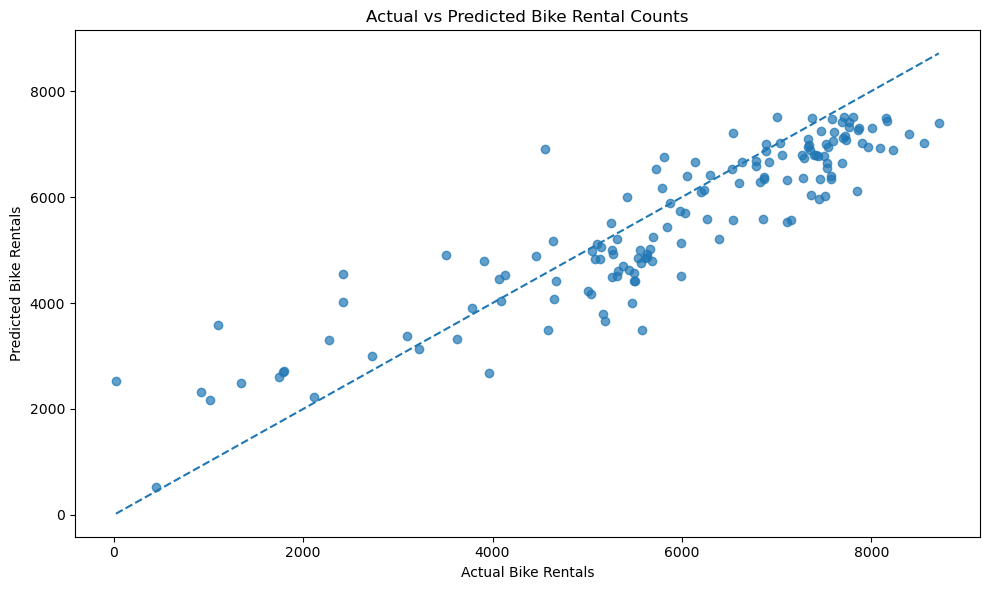

In [88]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.scatter(
    evaluation_df["Actual"],
    evaluation_df["Predicted"],
    alpha=0.7
)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    linestyle="--"
)

plt.xlabel("Actual Bike Rentals")
plt.ylabel("Predicted Bike Rentals")
plt.title("Actual vs Predicted Bike Rental Counts")

plt.tight_layout()
plt.show()

### Actual vs Predicted Bike Rental Analysis

The actual versus predicted scatter plot was used to visually evaluate the performance of the tuned Gradient Boosting model.

The majority of observations are distributed around the diagonal reference line, indicating that the model captures the general relationship between actual and predicted bike rental demand.

However, some deviations are visible:

- Several low-demand observations are overestimated.
- Some high-demand observations are underestimated.
- Prediction errors are more noticeable for certain observations at the extremes.

Overall, the visualization indicates that the model has a reasonable predictive relationship with actual rental demand, although further residual analysis is necessary to identify systematic prediction errors.

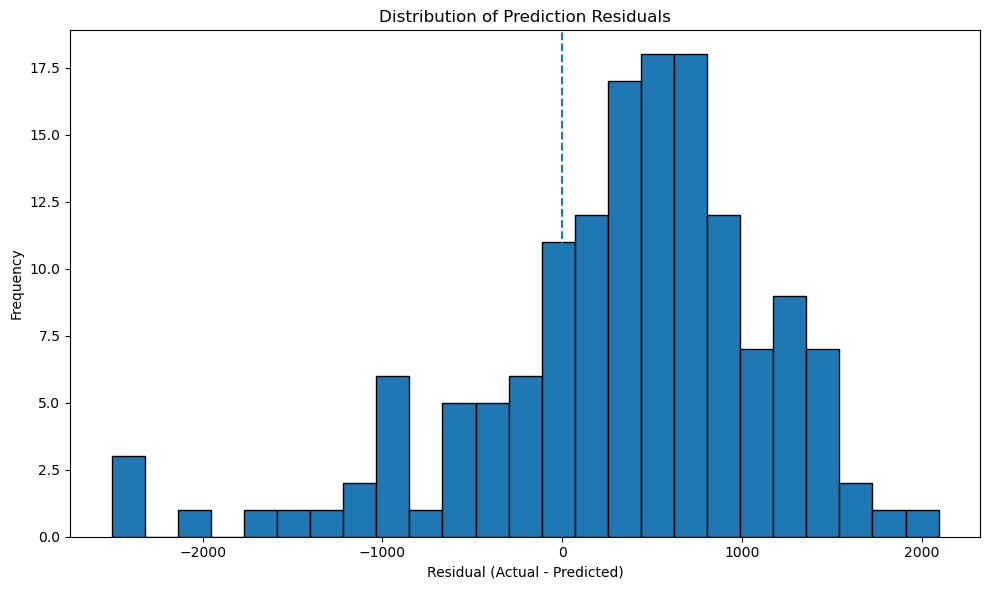

In [89]:
plt.figure(figsize=(10, 6))

plt.hist(
    evaluation_df["Residual"],
    bins=25,
    edgecolor="black"
)

plt.axvline(
    x=0,
    linestyle="--"
)

plt.xlabel("Residual (Actual - Predicted)")
plt.ylabel("Frequency")
plt.title("Distribution of Prediction Residuals")

plt.tight_layout()
plt.show()

### Residual Distribution Analysis

The residual distribution of the tuned Gradient Boosting model was examined using a histogram.

The following observations were made:

- Most residuals are concentrated between approximately 0 and 1,000.
- The distribution is not perfectly symmetrical around zero.
- A greater concentration of positive residuals suggests a tendency to underestimate actual bike rental demand.
- Some large negative residuals indicate occasional overestimation.
- Both positive and negative extreme errors are present.

Overall, the model captures the general rental demand pattern, but its prediction errors are not perfectly balanced. Further analysis of residuals against predicted values will help identify whether systematic error patterns exist.

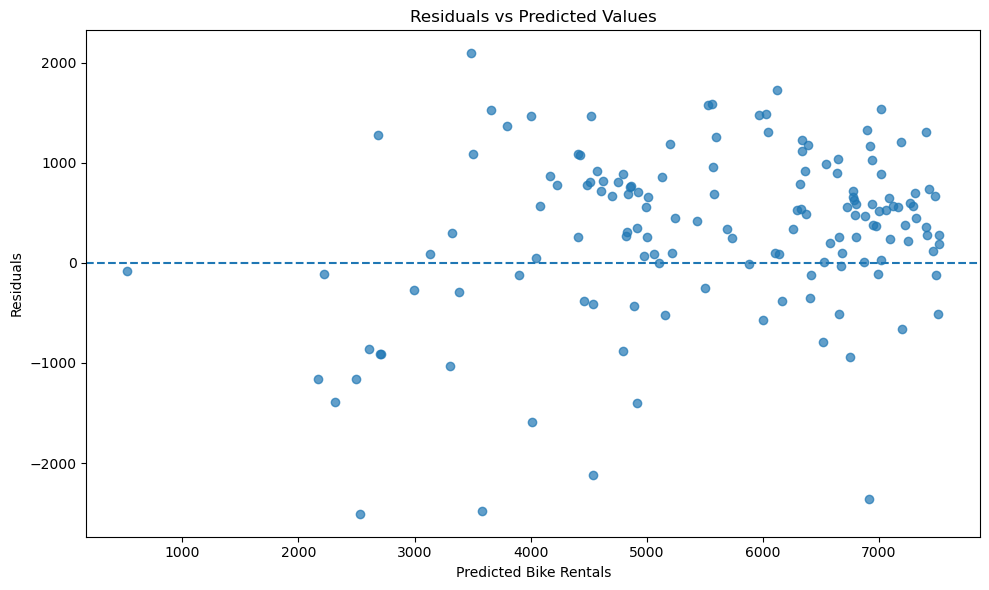

In [90]:
plt.figure(figsize=(10, 6))

plt.scatter(
    evaluation_df["Predicted"],
    evaluation_df["Residual"],
    alpha=0.7
)

plt.axhline(
    y=0,
    linestyle="--"
)

plt.xlabel("Predicted Bike Rentals")
plt.ylabel("Residuals")
plt.title("Residuals vs Predicted Values")

plt.tight_layout()
plt.show()

### Residuals vs Predicted Values Analysis

The residuals versus predicted values plot was examined to identify systematic prediction errors.

The following observations were made:

- A considerable number of residuals are positive, suggesting that the model frequently underestimates rental demand.
- Negative residuals indicate instances of overprediction.
- Some observations have large prediction errors, exceeding 2,000 rentals in absolute magnitude.
- Residuals are distributed on both sides of the zero reference line.
- No strong funnel-shaped pattern is clearly visible.

Overall, the model demonstrates reasonable predictive performance but still produces noticeable errors for certain observations. These findings indicate opportunities for further improvement in capturing variations in bike rental demand.

In [91]:
comparison_df = pd.concat(
    [
        initial_results,
        tuned_results_df
    ],
    ignore_index=True
)

comparison_df = comparison_df.sort_values(
    by="RMSE",
    ascending=True
).reset_index(drop=True)

comparison_df

,Model,MAE,MSE,RMSE,R2 Score,R2
0,Tuned Gradient Boosting,716.213303,7.885879e+05,888.024715,NaN,0.775600
1,Gradient Boosting,767.642449,8.985093e+05,947.897329,0.744320,NaN
2,Random Forest,895.637891,1.243358e+06,1115.059584,0.646190,NaN
3,Tuned Random Forest,917.025862,1.268618e+06,1126.329538,NaN,0.639002
4,Linear Regression,908.408726,1.419755e+06,1191.534871,0.595995,NaN
5,Decision Tree,1223.442177,2.338045e+06,1529.066546,0.334687,NaN
6,KNN,1361.874830,2.665480e+06,1632.629788,0.241512,NaN
7,SVR,2238.277891,6.269314e+06,2503.859824,-0.783994,NaN


In [92]:
# Standardise the R2 column name

initial_results_clean = initial_results.rename(
    columns={"R2 Score": "R2"}
)

tuned_results_clean = tuned_results_df.rename(
    columns={"R2 Score": "R2"}
)

# Combine all model results

comparison_df = pd.concat(
    [initial_results_clean, tuned_results_clean],
    ignore_index=True
)

# Sort models by RMSE

comparison_df = comparison_df.sort_values(
    by="RMSE",
    ascending=True
).reset_index(drop=True)

comparison_df.round(3)

,Model,MAE,MSE,RMSE,R2
0,Tuned Gradient Boosting,716.213,788587.895,888.025,0.776
1,Gradient Boosting,767.642,898509.347,947.897,0.744
2,Random Forest,895.638,1243357.876,1115.060,0.646
3,Tuned Random Forest,917.026,1268618.228,1126.330,0.639
4,Linear Regression,908.409,1419755.350,1191.535,0.596
5,Decision Tree,1223.442,2338044.503,1529.067,0.335
6,KNN,1361.875,2665480.026,1632.630,0.242
7,SVR,2238.278,6269314.019,2503.860,-0.784


## Model Comparison Report

Eight regression models were evaluated using the same chronological test dataset.

The models included Linear Regression, Decision Tree, Random Forest, Gradient Boosting, K-Nearest Neighbors, Support Vector Regression, Tuned Gradient Boosting and Tuned Random Forest.

### Key Findings

1. Tuned Gradient Boosting achieved the lowest RMSE of 888.02 and the lowest MAE of 716.21.
2. Its R² score of 0.7756 indicates that it explains approximately 77.56% of the variation in bike rental demand on the test dataset.
3. Hyperparameter tuning improved Gradient Boosting compared with its baseline version.
4. Random Forest performed reasonably well, but its tuned version did not improve upon the baseline.
5. Linear Regression provided a competitive baseline, while Decision Tree and KNN showed weaker predictive performance.
6. SVR produced the weakest results, with a negative R² score.

### Overall Comparison

Tuned Gradient Boosting demonstrated the strongest predictive performance across the evaluated models. It achieved the best combination of MAE, RMSE and R².

Therefore, it is the leading candidate for final model selection, subject to the remaining validation and practical considerations.

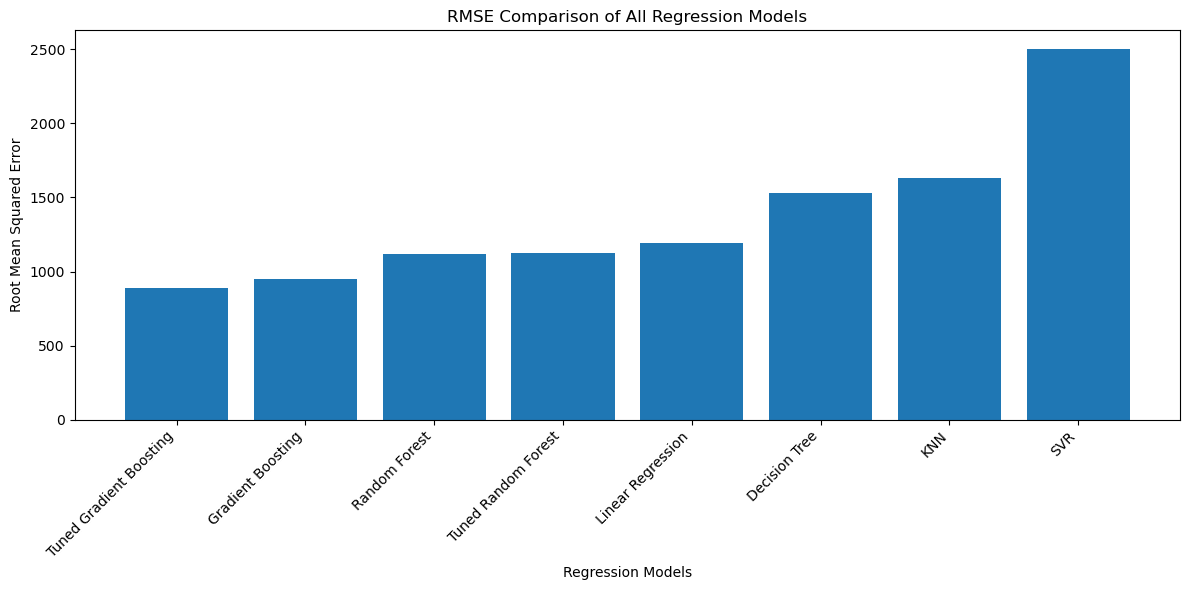

In [93]:
plt.figure(figsize=(12, 6))

plt.bar(
    comparison_df["Model"],
    comparison_df["RMSE"]
)

plt.title("RMSE Comparison of All Regression Models")
plt.xlabel("Regression Models")
plt.ylabel("Root Mean Squared Error")

plt.xticks(rotation=45, ha="right")

plt.tight_layout()
plt.show()

## Best Model Selection

After evaluating and comparing all eight regression models, Tuned Gradient Boosting was selected as the best-performing model.

### Reasons for Selection

1. It achieved the lowest Mean Absolute Error (716.21).
2. It achieved the lowest Root Mean Squared Error (888.02).
3. It achieved the highest R² score (0.7756).
4. Hyperparameter tuning improved its performance compared with the baseline Gradient Boosting model.
5. Its performance was stronger than the other evaluated regression algorithms on the test dataset.

### Selected Model

**Tuned Gradient Boosting Regressor**

The selected model explains approximately 77.56% of the variation in daily bike rental demand on the test dataset.

It is recommended as the best candidate for predicting daily bike rental demand. Further validation on newer data would be necessary before deployment in a real business environment.

In [94]:
# Select the best tuned model

final_model = gb_grid_search.best_estimator_

# Verify model configuration

print("Selected Model:")
print(final_model.named_steps["model"])

print("\nBest Hyperparameters:")
print(gb_grid_search.best_params_)

print("\nFinal Test Performance:")
print(comparison_df.iloc[0])

Selected Model:
GradientBoostingRegressor(max_depth=2, n_estimators=300, random_state=42,
                          subsample=0.8)

Best Hyperparameters:
{'model__learning_rate': 0.1, 'model__max_depth': 2, 'model__n_estimators': 300, 'model__subsample': 0.8}

Final Test Performance:
Model    Tuned Gradient Boosting
MAE                   716.213303
MSE                788587.894868
RMSE                  888.024715
R2                        0.7756
Name: 0, dtype: object


In [95]:
import joblib
import os

# Create folder for saved models
os.makedirs("saved_models", exist_ok=True)

# Save complete trained pipeline
model_path = "saved_models/best_bike_rental_model.pkl"

joblib.dump(final_model, model_path)

print("Model saved successfully!")
print("Location:", model_path)

Model saved successfully!
Location: saved_models/best_bike_rental_model.pkl


In [96]:
# Load the saved model

loaded_model = joblib.load(model_path)

# Generate predictions using loaded model

loaded_predictions = loaded_model.predict(X_test)

# Compare predictions

print("Original model predictions:")
print(y_pred_best[:5])

print("\nLoaded model predictions:")
print(loaded_predictions[:5])

# Verify predictions are identical

print("\nPrediction verification:",
      np.allclose(y_pred_best, loaded_predictions))

Original model predictions:
[6791.34404894 6639.57904818 6729.36170268 6167.33957937 6419.03035112]

Loaded model predictions:
[6791.34404894 6639.57904818 6729.36170268 6167.33957937 6419.03035112]

Prediction verification: True


### Final Model Saving and Verification

The selected Tuned Gradient Boosting model was saved using Joblib in Pickle format.

The complete trained pipeline, including preprocessing and the regression estimator, was saved for future reuse.

The saved model was subsequently loaded and tested using the test dataset.

The predictions generated by the loaded model were compared with those from the original trained model. Identical predictions confirmed that the model was successfully saved and restored.

**Final selected model:** Tuned Gradient Boosting Regressor.

**Test RMSE:** 888.02

**Test MAE:** 716.21

**Test R²:** 0.7756

### Final Model Selection Summary

Tuned Gradient Boosting was selected as the final model after comparing eight regression algorithms.

The model achieved the following test performance:

- MAE: 716.21
- MSE: 788,587.89
- RMSE: 888.02
- R²: 0.7756

The selected model was saved using Joblib and successfully loaded again. Prediction verification confirmed that the original and restored models produced identical results.

The complete preprocessing and prediction pipeline is preserved for future use.

# 16. Final Conclusion

## Project Overview

The objective of this project was to analyse historical bike rental data and develop a machine learning model capable of predicting daily bike rental demand using environmental, seasonal and calendar-related information.

The analysis used the daily and hourly bike rental datasets.

## Data Analysis Findings

Exploratory data analysis revealed several important demand patterns:

- Bike rental demand varied significantly across seasons and months.
- Fall recorded the highest average daily rental demand, while spring recorded the lowest.
- Clear weather conditions were associated with higher average rental demand.
- Weekday hourly demand showed prominent morning and evening peaks.
- Weekend demand was stronger during midday and afternoon hours.
- Temperature showed a positive association with daily rental demand.

Statistical analysis also identified significant differences in rental demand across observed weather categories.

## Model Development

Eight regression models were developed and evaluated:

1. Linear Regression
2. Decision Tree
3. Random Forest
4. Gradient Boosting
5. K-Nearest Neighbors
6. Support Vector Regression
7. Tuned Gradient Boosting
8. Tuned Random Forest

Hyperparameter tuning was performed using GridSearchCV and TimeSeriesSplit cross-validation.

## Final Model Performance

Tuned Gradient Boosting was selected as the best-performing model.

| Evaluation Metric | Result |
|---|---:|
| MAE | 716.21 |
| MSE | 788,587.89 |
| RMSE | 888.02 |
| R² | 0.7756 |

The model explains approximately 77.56% of the variation in daily bike rental demand on the test dataset.

## Business Significance

A bike-sharing business could use this model as a supporting tool for estimating daily rental demand.

Potential applications include:

- Planning bicycle availability.
- Supporting operational resource allocation.
- Anticipating seasonal demand variations.
- Improving inventory and fleet planning.
- Supporting demand-based business decisions.

However, predictions should be considered alongside real-time demand information and operational conditions.

## Final Outcome

The project successfully completed data inspection, quality assessment, exploratory analysis, statistical testing, data cleaning, feature engineering, preprocessing, model development, hyperparameter tuning and model evaluation.

The selected model was saved and successfully restored using Joblib.

Overall, Tuned Gradient Boosting demonstrated the strongest predictive performance among the evaluated models and was selected as the final candidate for bike rental demand prediction.

# 17. Challenges Report

During the Bike Rental Prediction project, several analytical and modelling challenges were encountered.

### 1. Data Understanding

Understanding the relationship between daily and hourly datasets required additional investigation. Both datasets contained overlapping information but served different analytical purposes.

### 2. Data Quality Validation

Although the datasets contained no missing values or duplicate records, additional validation was necessary to verify date continuity, target consistency and categorical value ranges.

### 3. Target Leakage

The target variable `cnt` was calculated using `casual` and `registered` rental counts.

Including these two variables as model predictors would introduce target leakage. Therefore, they were removed before model development.

### 4. Feature Selection

Several variables contained overlapping information. For example, temperature and feeling temperature were highly correlated.

Calendar-related variables also contained overlapping information, requiring careful feature selection.

### 5. Time-Based Data Splitting

A chronological train-test split was used instead of a random split to preserve the time sequence of observations.

TimeSeriesSplit was also used during hyperparameter tuning to maintain temporal ordering during cross-validation.

### 6. Model Performance Differences

Different regression algorithms produced substantially different results.

Gradient Boosting performed better than the other baseline models, while SVR produced a negative R² score.

### 7. Hyperparameter Tuning

GridSearchCV was used to identify suitable model configurations.

Tuning improved Gradient Boosting performance, but Random Forest did not show an improvement on the final test dataset.

### 8. Prediction Errors

Residual analysis identified instances of both overprediction and underprediction.

The model also produced larger errors for certain observations, indicating that some demand variations were not fully captured.

### 9. Generalisation and Deployment

Although the selected model achieved good test performance, additional validation using newer data would be necessary before real-world deployment.

External factors such as special events, local disruptions and sudden changes in demand were not explicitly represented in the available features.

## Conclusion

The project provided practical experience in handling real-world datasets, performing exploratory and statistical analysis, developing regression models and evaluating predictive performance.

The challenges encountered highlighted the importance of data quality, leakage prevention, appropriate validation strategies and careful model selection.

In [98]:
# ============================================================
# BIKE RENTAL PREDICTION - MASTER PROJECT AUDIT
# ============================================================

import os
import numpy as np
import pandas as pd
import joblib
import warnings

warnings.filterwarnings("ignore")

audit_results = []

def check(name, condition, details=""):
    status = "PASS" if condition else "FAIL"

    audit_results.append({
        "Check": name,
        "Status": status,
        "Details": details
    })

    symbol = "PASS" if condition else "FAIL"
    print(f"[{symbol}] {name}")

    if details:
        print("      ", details)


print("=" * 65)
print("       BIKE RENTAL PREDICTION - MASTER AUDIT")
print("=" * 65)


# 1. DATASET CHECKS
check(
    "Daily dataset loaded",
    "day_df" in globals() and isinstance(day_df, pd.DataFrame),
    f"Shape: {day_df.shape if 'day_df' in globals() else 'Not found'}"
)

check(
    "Hourly dataset loaded",
    "hour_df" in globals() and isinstance(hour_df, pd.DataFrame),
    f"Shape: {hour_df.shape if 'hour_df' in globals() else 'Not found'}"
)


# 2. DATA QUALITY
if "day_df" in globals():

    check(
        "No missing values in daily dataset",
        day_df.isnull().sum().sum() == 0
    )

    check(
        "No duplicate rows in daily dataset",
        day_df.duplicated().sum() == 0
    )

    check(
        "Target variable exists",
        "cnt" in day_df.columns
    )

    check(
        "Target values are valid",
        (day_df["cnt"] > 0).all()
    )

    check(
        "Rental count consistency",
        (day_df["cnt"] == day_df["casual"] + day_df["registered"]).all()
    )


# 3. CLEANED DATA CHECKS
check(
    "Cleaned dataset exists",
    "clean_df" in globals() and isinstance(clean_df, pd.DataFrame)
)

if "clean_df" in globals():

    check(
        "No missing values after cleaning",
        clean_df.isnull().sum().sum() == 0
    )

    check(
        "Target leakage columns removed",
        not any(
            col in clean_df.columns
            for col in ["casual", "registered"]
        )
    )


# 4. FEATURE AND TARGET CHECKS
check(
    "Feature matrix exists",
    "X" in globals()
)

check(
    "Target vector exists",
    "y" in globals()
)

if "X" in globals() and "y" in globals():

    check(
        "Feature-target dimensions match",
        len(X) == len(y)
    )

    check(
        "Target leakage avoided in predictors",
        not any(col in X.columns for col in ["cnt", "casual", "registered"])
    )


# 5. PREPROCESSING
check(
    "Preprocessor exists",
    "preprocessor" in globals()
)

check(
    "Numerical transformer exists",
    "numerical_transformer" in globals()
)

check(
    "Categorical transformer exists",
    "categorical_transformer" in globals()
)


# 6. TRAIN-TEST SPLIT
check(
    "Training and testing datasets exist",
    all(
        name in globals()
        for name in ["X_train", "X_test", "y_train", "y_test"]
    )
)

if all(name in globals() for name in ["X_train", "X_test", "y_train", "y_test"]):

    check(
        "Training dimensions match",
        len(X_train) == len(y_train)
    )

    check(
        "Testing dimensions match",
        len(X_test) == len(y_test)
    )

    check(
        "Chronological split maintained",
        X_train.index.max() < X_test.index.min()
    )


# 7. BASELINE MODEL CHECKS
expected_models = [
    "Linear Regression",
    "Decision Tree",
    "Random Forest",
    "Gradient Boosting",
    "KNN",
    "SVR"
]

check(
    "Baseline models trained",
    "trained_models" in globals()
    and all(name in trained_models for name in expected_models)
)


# 8. HYPERPARAMETER TUNING
check(
    "Gradient Boosting tuning completed",
    "gb_grid_search" in globals()
    and hasattr(gb_grid_search, "best_estimator_")
)

check(
    "Random Forest tuning completed",
    "rf_grid_search" in globals()
    and hasattr(rf_grid_search, "best_estimator_")
)


# 9. MODEL EVALUATION
check(
    "Baseline evaluation results exist",
    "initial_results" in globals()
    and len(initial_results) >= 6
)

check(
    "Tuned evaluation results exist",
    "tuned_results_df" in globals()
    and len(tuned_results_df) >= 2
)


# 10. MODEL COMPARISON
check(
    "Model comparison exists",
    "comparison_df" in globals()
    and len(comparison_df) >= 8
)

if "comparison_df" in globals():

    check(
        "Comparison metrics are valid",
        all(
            col in comparison_df.columns
            for col in ["MAE", "RMSE", "R2"]
        )
        and np.isfinite(
            comparison_df[["MAE", "RMSE", "R2"]].to_numpy()
        ).all()
    )


# 11. FINAL MODEL
check(
    "Final model selected",
    "final_model" in globals()
)

if "final_model" in globals():

    check(
        "Final model is tuned Gradient Boosting",
        final_model is gb_grid_search.best_estimator_
    )


# 12. FINAL METRICS
if "comparison_df" in globals():

    best_row = comparison_df.loc[
        comparison_df["RMSE"].idxmin()
    ]

    check(
        "Final model has lowest RMSE",
        best_row["Model"] == "Tuned Gradient Boosting",
        f"Best model: {best_row['Model']}"
    )

    check(
        "Final model metrics are finite",
        np.isfinite([
            best_row["MAE"],
            best_row["RMSE"],
            best_row["R2"]
        ]).all()
    )


# 13. PREDICTION CHECKS
check(
    "Final predictions generated",
    "y_pred_best" in globals()
)

if "y_pred_best" in globals():

    check(
        "Predictions contain valid values",
        np.isfinite(y_pred_best).all()
    )

    check(
        "Prediction count matches test data",
        len(y_pred_best) == len(y_test)
    )


# 14. RESIDUAL CHECKS
check(
    "Residual analysis exists",
    "evaluation_df" in globals()
    and all(
        col in evaluation_df.columns
        for col in ["Actual", "Predicted", "Residual"]
    )
)

if "evaluation_df" in globals():

    check(
        "Residual calculations are correct",
        np.allclose(
            evaluation_df["Actual"] - evaluation_df["Predicted"],
            evaluation_df["Residual"]
        )
    )


# 15. SAVED MODEL CHECK
model_path = "saved_models/best_bike_rental_model.pkl"

check(
    "Saved model file exists",
    os.path.exists(model_path),
    model_path
)

if os.path.exists(model_path):

    try:
        loaded_model = joblib.load(model_path)

        check(
            "Saved model loads successfully",
            True
        )

        saved_predictions = loaded_model.predict(X_test)

        check(
            "Saved model predictions match",
            np.allclose(saved_predictions, y_pred_best)
        )

    except Exception as e:

        check(
            "Saved model verification",
            False,
            str(e)
        )


# 16. FINAL AUDIT REPORT
audit_df = pd.DataFrame(audit_results)

passed = (audit_df["Status"] == "PASS").sum()
failed = (audit_df["Status"] == "FAIL").sum()
total = len(audit_df)

print("\n" + "=" * 65)
print("                 FINAL AUDIT REPORT")
print("=" * 65)

print(audit_df.to_string(index=False))

print("\nTotal Checks:", total)
print("Passed:", passed)
print("Failed:", failed)

print("Audit Pass Rate:", round((passed / total) * 100, 2), "%")

print("\n" + "=" * 65)

if failed == 0:
    print("ALL AUTOMATED CHECKS PASSED")
    print("PROJECT PASSES THE AUTOMATED AUDIT")
else:
    print("PROJECT NEEDS CORRECTIONS")
    print("REVIEW THE FAILED CHECKS ABOVE")

print("=" * 65)

       BIKE RENTAL PREDICTION - MASTER AUDIT
[PASS] Daily dataset loaded
       Shape: (731, 16)
[PASS] Hourly dataset loaded
       Shape: (17379, 18)
[PASS] No missing values in daily dataset
[PASS] No duplicate rows in daily dataset
[PASS] Target variable exists
[PASS] Target values are valid
[PASS] Rental count consistency
[PASS] Cleaned dataset exists
[PASS] No missing values after cleaning
[PASS] Target leakage columns removed
[PASS] Feature matrix exists
[PASS] Target vector exists
[PASS] Feature-target dimensions match
[PASS] Target leakage avoided in predictors
[PASS] Preprocessor exists
[PASS] Numerical transformer exists
[PASS] Categorical transformer exists
[PASS] Training and testing datasets exist
[PASS] Training dimensions match
[PASS] Testing dimensions match
[PASS] Chronological split maintained
[PASS] Baseline models trained
[PASS] Gradient Boosting tuning completed
[PASS] Random Forest tuning completed
[PASS] Baseline evaluation results exist
[PASS] Tuned evaluation 